# [GSE163214](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE163214)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2023-02-03
> - Modified: 2025-01-12

# 1. Experimental Design

> 	Gene expression analysis in HeLa Kyoto cells upon knockdown of JAZF1.
> - Procida, Tara, Tobias Friedrich, and et al. 2021. "JAZF1, A Novel p400/TIP60/NuA4 Complex Member, Regulates H2A.Z Acetylation at Regulatory Regions" International Journal of Molecular Sciences 22, no. 2: 678. https://doi.org/10.3390/ijms22020678.
> - polyA RNA-seq
> - Illumina NextSeq 550, SE75
> - GRCh38

| Sample | Organism | Cell | Source | Treatment | Batch |
| - | - | - | - | - | - |
| Control | Homo sapiens | HeLa Kyoto | Cervix carcinoma cells | Control | batch1 (rep1-2), batch2 (rep3-5) |
| siJAZF1 | Homo sapiens | HeLa Kyoto | Cervix carcinoma cells | JAZF1 siRNA | batch1 (rep1-2), batch2 (rep3-5) |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Hs_Hela_JAZF1_GSE163214"

In [3]:
raw_counts <- file.path(data_dir, "GSE163214_raw_counts_GRCh38.p13_NCBI.tsv.gz") |>
    read.table(header = TRUE, sep = "\t", row.names = 1) |> 
    as.matrix()

dim(raw_counts)

[1] 39376    10

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(Accession = _) |>
    mutate(
        Cell = "Hela",
        Group = c("Control", "shJAZF1") |> rep(times = 5) |> 
            factor(levels = c("Control", "shJAZF1")), 
        Replicate = paste0("rep", seq(1, 5)) |> rep(each = 2) |>
            factor(),
        Batch = c(rep("batch1", times = 4), rep("batch2", times = 6)) |>
            factor(),
        sample = paste(Group, Replicate, sep = "_")) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Accession,Cell,Group,Replicate,Batch
,<chr>,<chr>,<fct>,<fct>,<fct>
Control_rep1,GSM4975190,Hela,Control,rep1,batch1
Control_rep2,GSM4975192,Hela,Control,rep2,batch1
Control_rep3,GSM4975194,Hela,Control,rep3,batch2
Control_rep4,GSM4975196,Hela,Control,rep4,batch2
Control_rep5,GSM4975198,Hela,Control,rep5,batch2
shJAZF1_rep1,GSM4975191,Hela,shJAZF1,rep1,batch1
shJAZF1_rep2,GSM4975193,Hela,shJAZF1,rep2,batch1
shJAZF1_rep3,GSM4975195,Hela,shJAZF1,rep3,batch2
shJAZF1_rep4,GSM4975197,Hela,shJAZF1,rep4,batch2


In [5]:
anno_gene <- file.path(data_dir, "Human.GRCh38.p13.annot.tsv.gz") |>
    data.table::fread(header = TRUE, sep = "\t", quote = "") |>
    select(GeneID, symbol = Symbol, type = GeneType, basepairs = Length) |>
    mutate(GeneID = as.character(GeneID)) |> 
    column_to_rownames("GeneID") |>
    DataFrame()

anno_gene

DataFrame with 39376 rows and 3 columns
               symbol           type basepairs
          <character>    <character> <integer>
100287102     DDX11L1         pseudo      1652
653635         WASH7P         pseudo      1769
102466751   MIR6859-1          ncRNA        68
107985730 MIR1302-2HG          ncRNA       538
100302278   MIR1302-2          ncRNA       138
...               ...            ...       ...
4541              ND6 protein-coding       525
4556             TRNE           tRNA        69
4519             CYTB protein-coding      1141
4576             TRNT           tRNA        66
4571             TRNP           tRNA        68

In [6]:
colnames(raw_counts) <- rownames(coldata)[
    match(colnames(raw_counts), coldata$Accession)]

raw_counts <- raw_counts[, rownames(coldata)]

## 2). Object Construction

In [7]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 39376 10 
metadata(0):
assays(1): counts
rownames(39376): 100287102 653635 ... 4576 4571
rowData names(3): symbol type basepairs
colnames(10): Control_rep1 Control_rep2 ... shJAZF1_rep4 shJAZF1_rep5
colData names(5): Accession Cell Group Replicate Batch

In [8]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene, 
    colData = coldata, design = ~ Batch + Group)
dds

class: DESeqDataSet 
dim: 39376 10 
metadata(1): version
assays(1): counts
rownames(39376): 100287102 653635 ... 4576 4571
rowData names(3): symbol type basepairs
colnames(10): Control_rep1 Control_rep2 ... shJAZF1_rep4 shJAZF1_rep5
colData names(5): Accession Cell Group Replicate Batch

In [9]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [10]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 14087 
 Remove: 25289 
 Retention rate: 35.78 %


In [11]:
design <- model.matrix(~ group + Batch, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 14004 
 Remove: 25372 
 Retention rate: 35.56 %


## 4). Normalization

In [12]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [13]:
dds <- estimateSizeFactors(dds)
# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)

In [14]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [15]:
design <- model.matrix(~ group + Batch, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [16]:
rld <- rlog(dds, blind = FALSE)

In [17]:
suppressPackageStartupMessages(library(vsn))

In [18]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [19]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


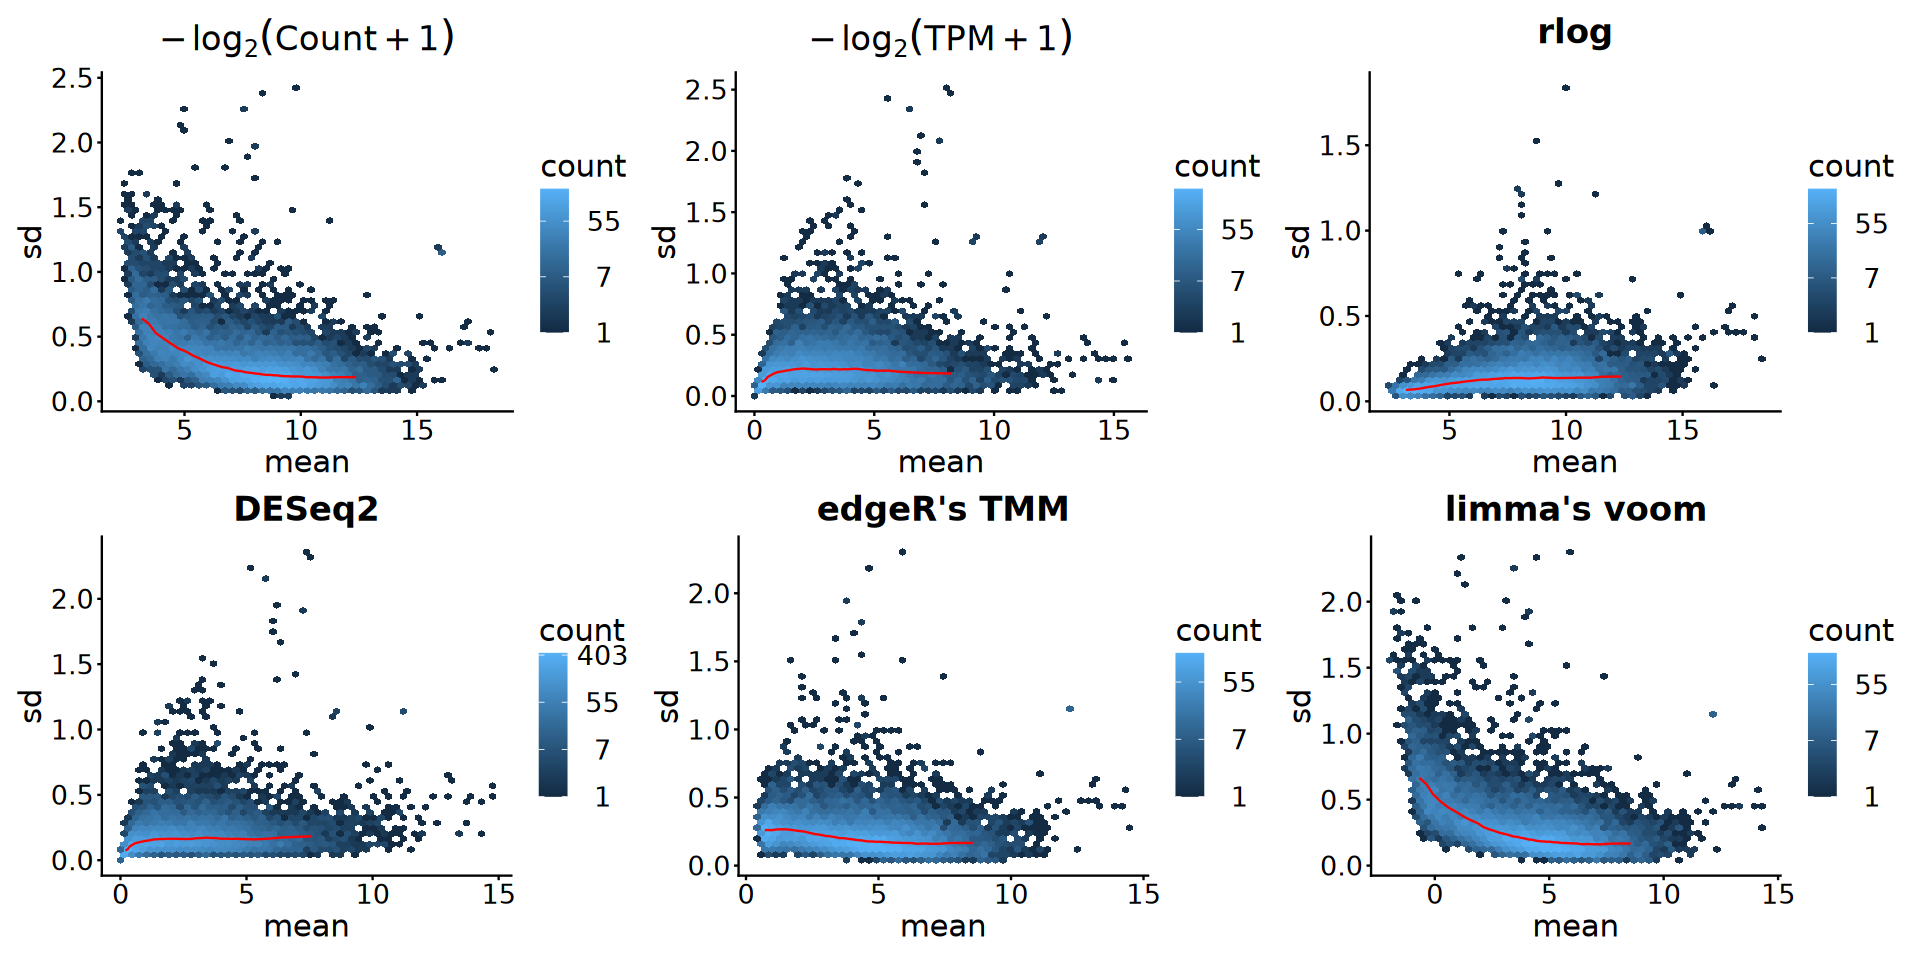

In [20]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 3. Exploration

In [21]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [22]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

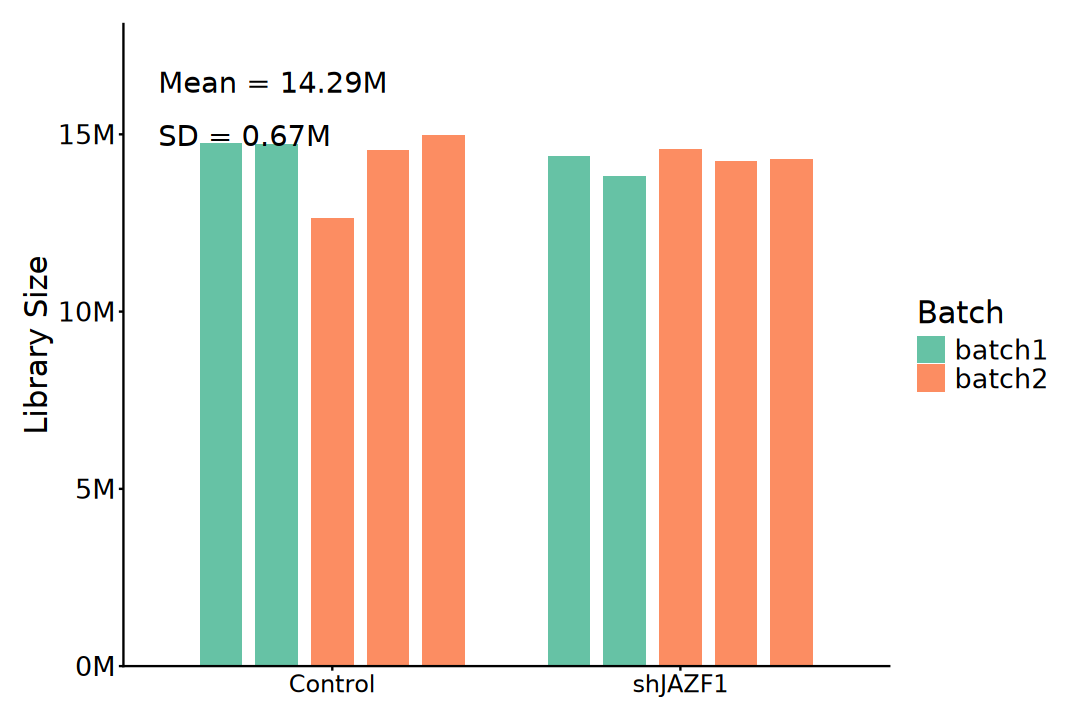

In [23]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize)) +
    geom_col(
        aes(fill = Batch, group = Sample), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, show.legend = TRUE) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6, 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.0,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6, 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 14),
        axis.text.y = element_text(size = 16))

## 2). PCA

In [24]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [25]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [26]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Batch), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [27]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Batch", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [28]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Batch), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [29]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [30]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Batch), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

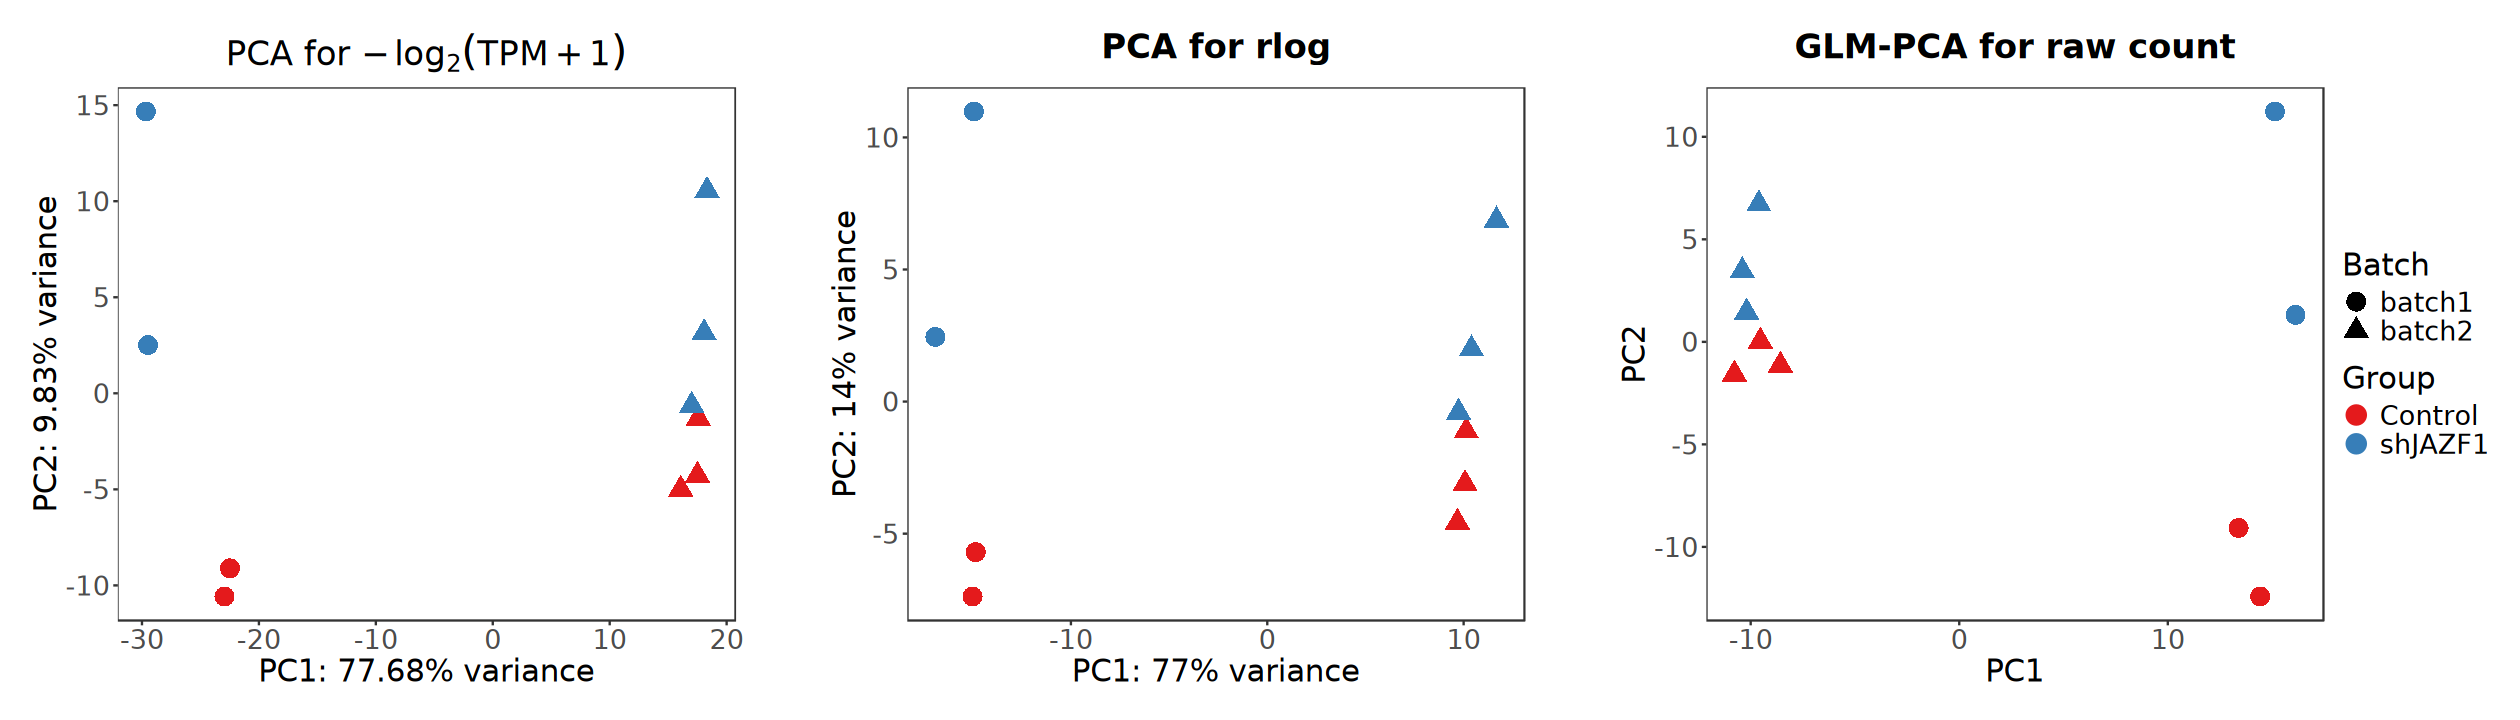

In [31]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [32]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

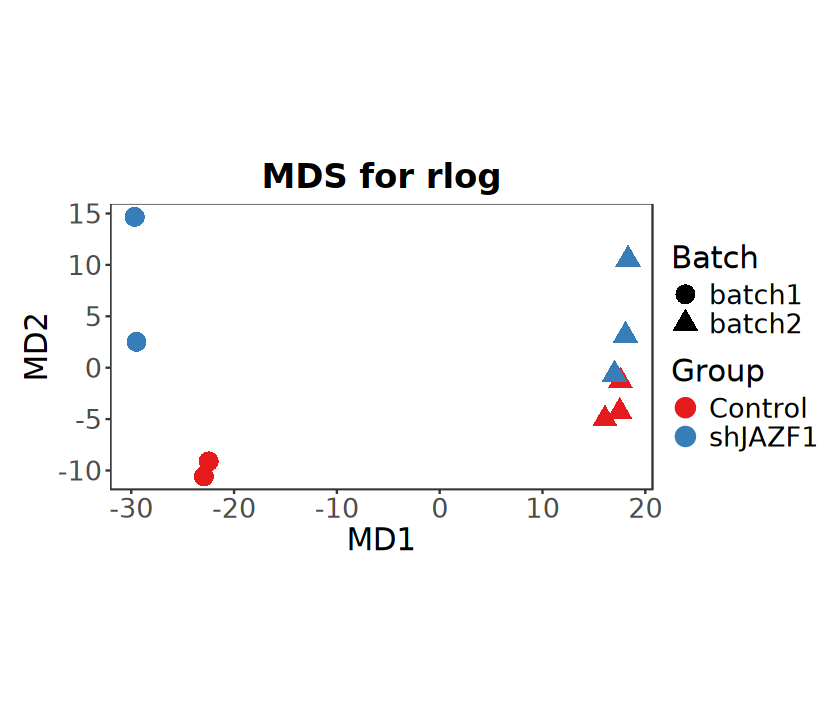

In [33]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Batch), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [34]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

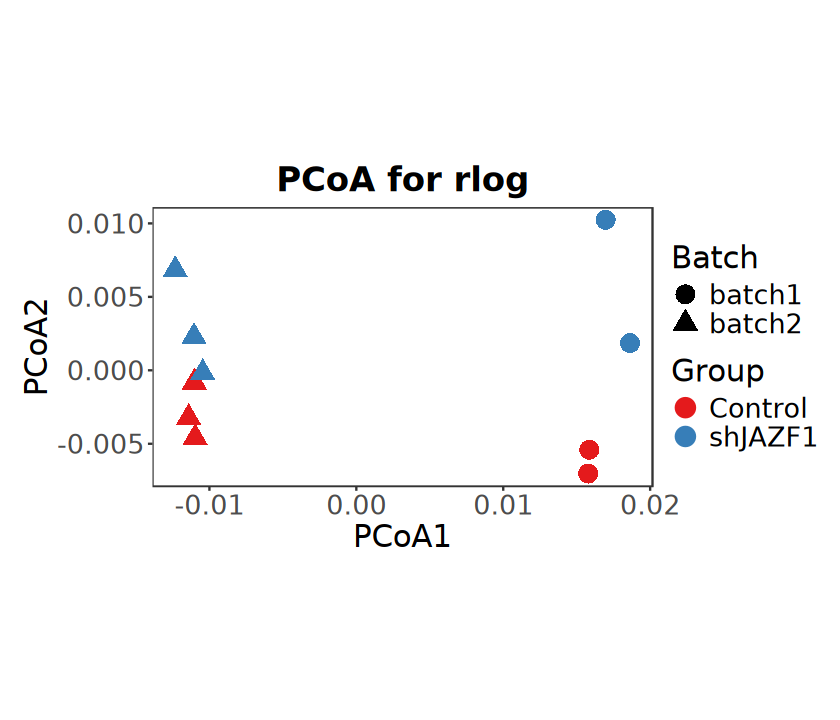

In [35]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Batch), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [36]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Batch, Group)

In [37]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
batch_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Batch)),
    levels(eSet$Batch))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Batch = batch_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [38]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

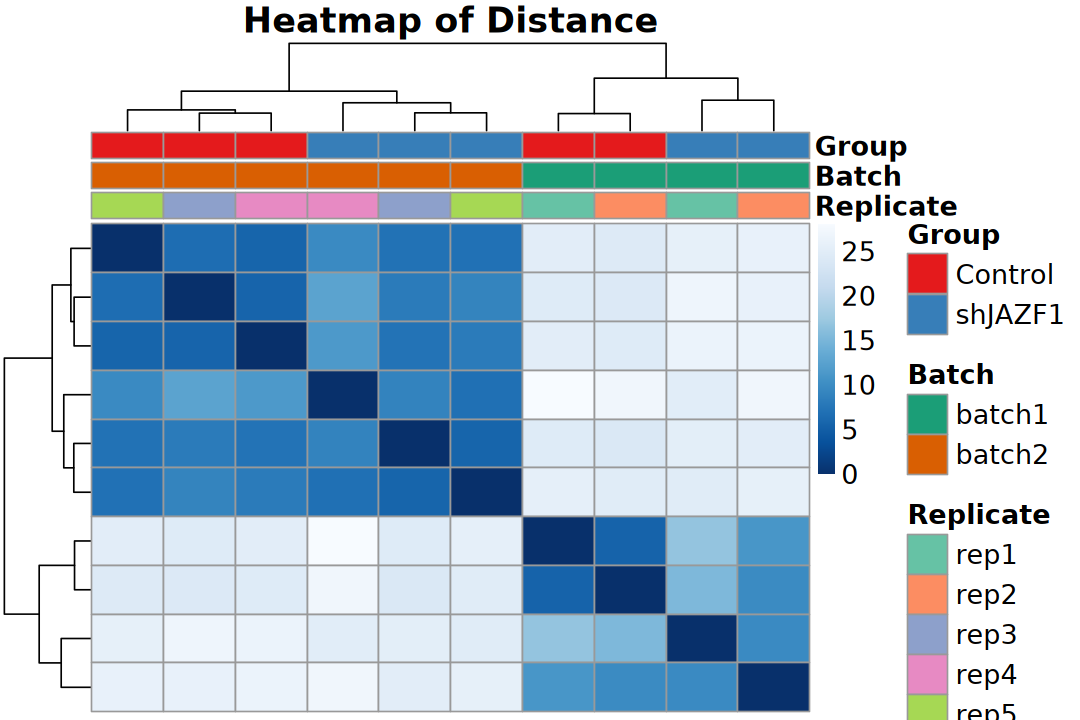

In [39]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [40]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

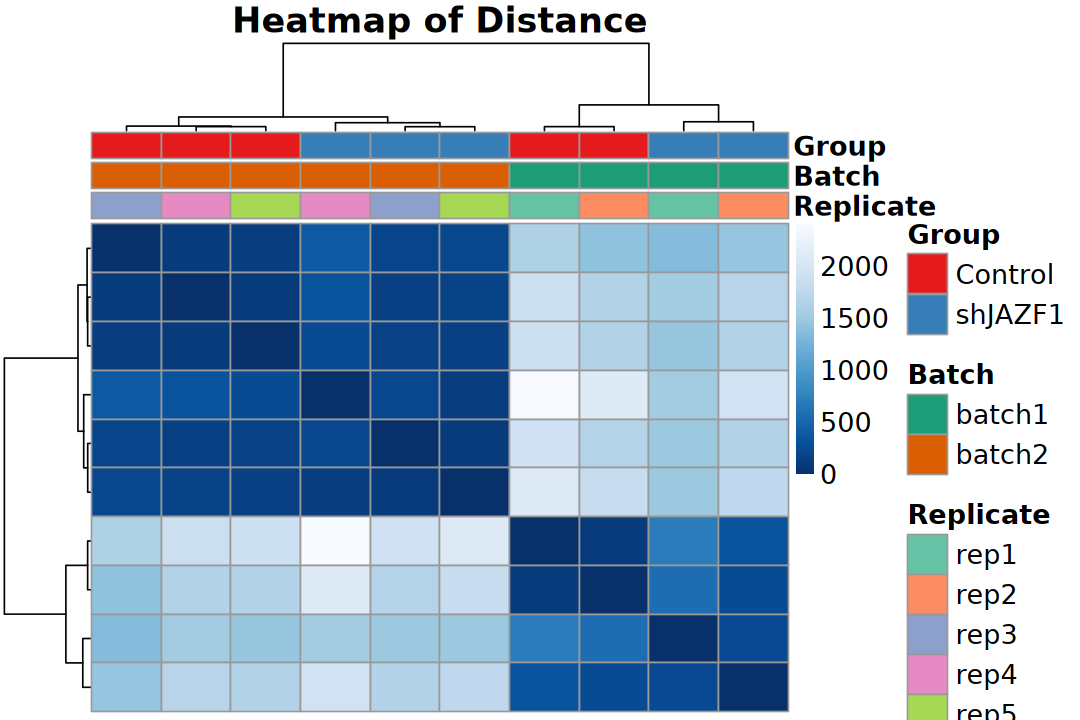

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [42]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

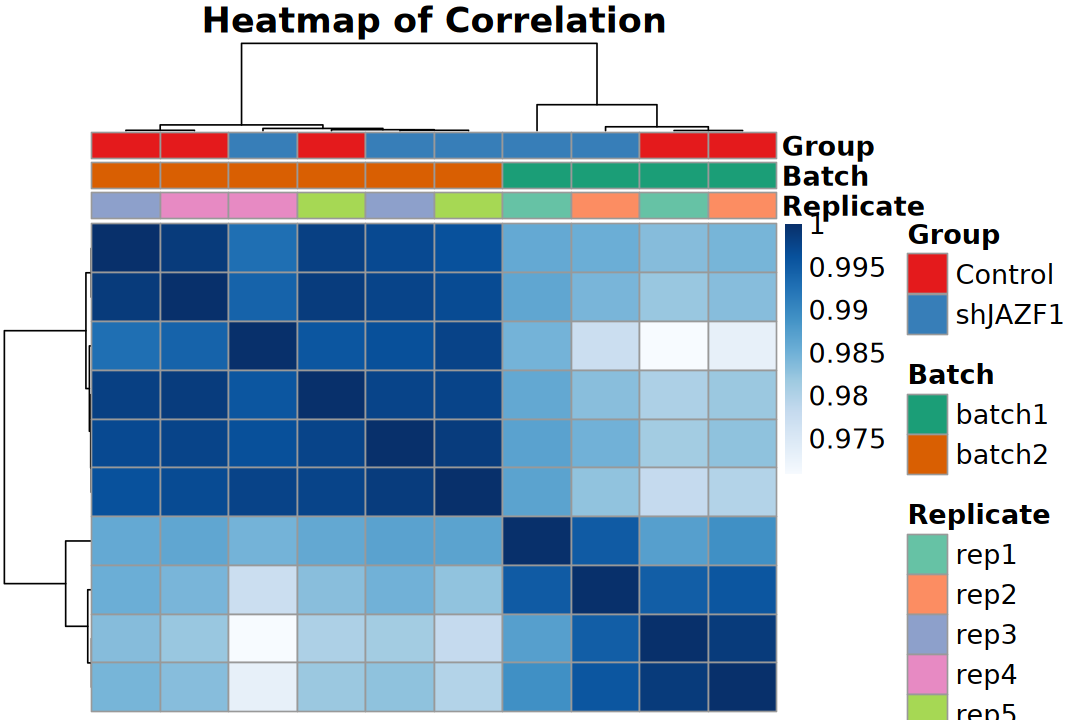

In [43]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

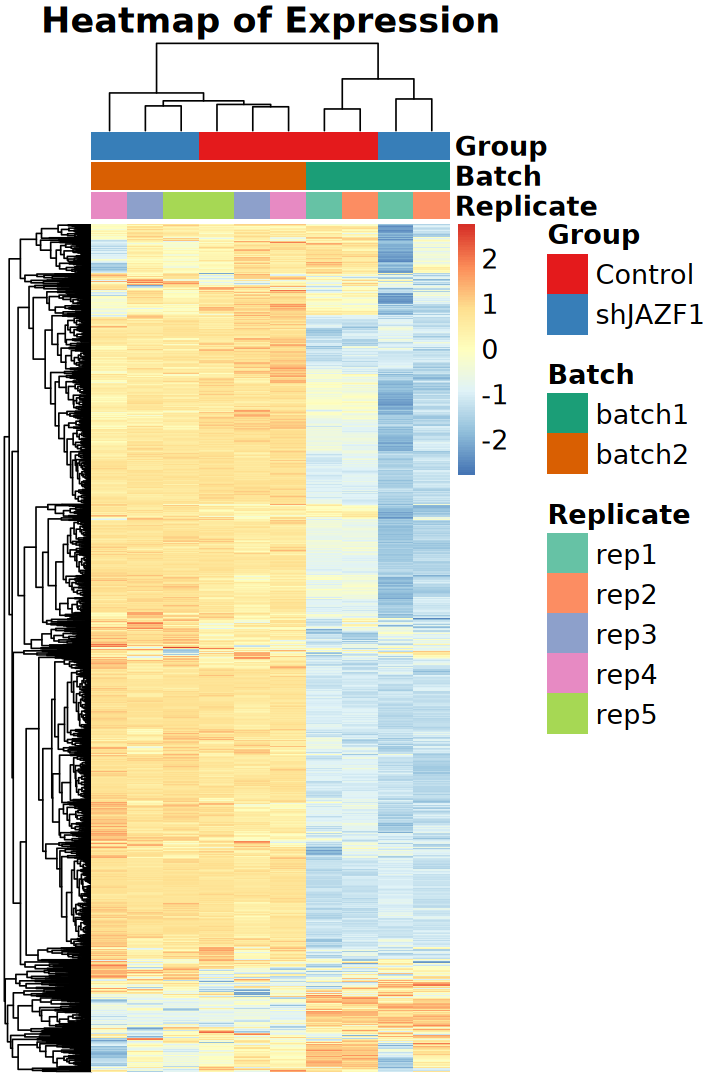

In [44]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 4. Batch Effect

## 1). Quantifying Variation

### a). Variance Explained

In [45]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

In [46]:
fit <- lm(pca_res$x[, 1] ~ Batch + Group, data = colData(eSet))
fit
ano <- anova(fit)
ano


Call:
lm(formula = pca_res$x[, 1] ~ Batch + Group, data = colData(eSet))

Coefficients:
 (Intercept)   Batchbatch2  GroupshJAZF1  
     -24.995        43.571        -2.296  


,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Batch,1,4556.28011,4556.280108,853.492193,1.417554e-08
Group,1,13.18327,13.183274,2.469519,1.600680e-01
Residuals,7,37.36878,5.338397,NA,NA


In [47]:
anova_df <- lapply(seq(1, 5), function(index) {
    lm(pca_res$x[, index] ~ Batch + Group, data = colData(eSet)) |>
        anova() |> as.data.frame() |> 
        rownames_to_column("Factor") |> 
        mutate(
            Prop = `Sum Sq` / sum(`Sum Sq`),
            PC = paste0("PC", index))
}) |> bind_rows() |>
    mutate(
        Factor = factor(Factor, levels = c("Batch", "Group", "Residuals")),
        PC = factor(PC))

head(anova_df)

,Factor,Df,Sum Sq,Mean Sq,F value,Pr(>F),Prop,PC
,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,Batch,1,4556.280108,4556.280108,853.49219260,1.417554e-08,0.989026721,PC1
2,Group,1,13.183274,13.183274,2.46951932,1.600680e-01,0.002861679,PC1
3,Residuals,7,37.368779,5.338397,NA,NA,0.008111600,PC1
4,Batch,1,2.623315,2.623315,0.08573094,7.781652e-01,0.004499393,PC2
5,Group,1,366.218417,366.218417,11.96816030,1.055466e-02,0.628121581,PC2
6,Residuals,7,214.195737,30.599391,NA,NA,0.367379026,PC2


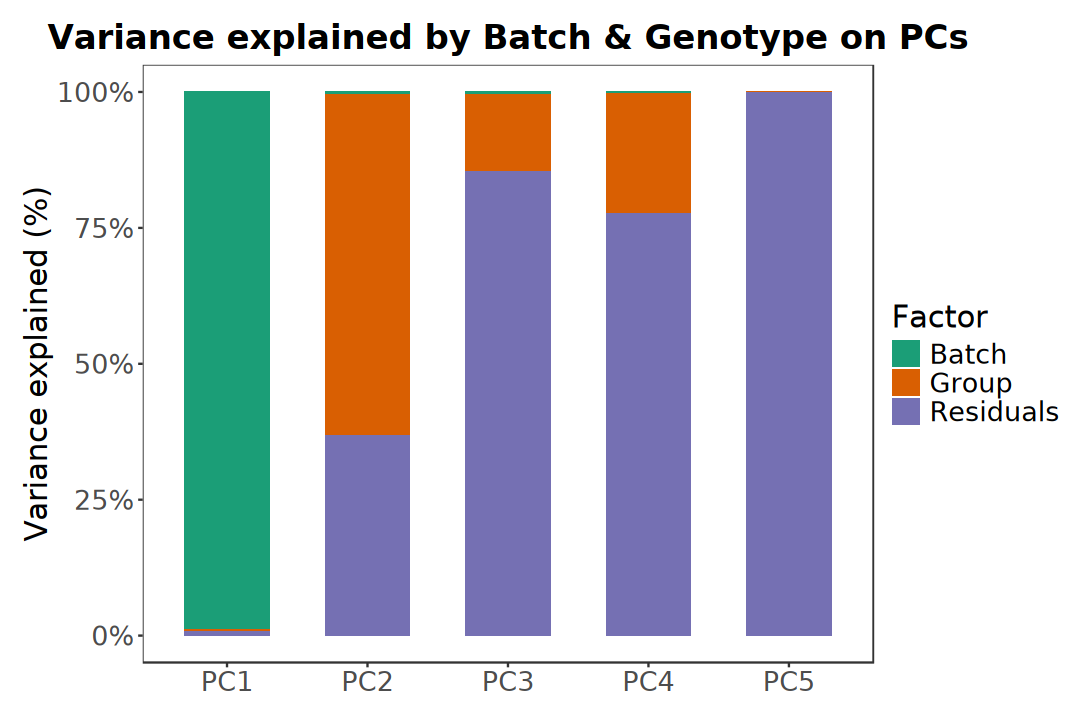

In [48]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anova_df, aes(x = PC, y = Prop, fill = Factor)) +
    geom_bar(stat = "identity", width = 0.6) +
    scale_fill_brewer(palette = "Dark2") +
    scale_y_continuous(labels = scales::percent_format(accuracy = 1)) +
    labs(
        title = "Variance explained by Batch & Genotype on PCs",
        x = NULL, y = "Variance explained (%)") +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [49]:
# suppressPackageStartupMessages(library(vegan))

dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

# Permutational Multivariate Analysis of Variance Using Distance Matrices
ado_res <- vegan::adonis2(
    dist_mat ~ Batch + Group, 
    data = colData(eSet), permutations = 999)

print(ado_res)

Permutation test for adonis under reduced model
Permutation: free
Number of permutations: 999

vegan::adonis2(formula = dist_mat ~ Batch + Group, data = colData(eSet), permutations = 999)
         Df SumOfSqs      R2      F Pr(>F)    
Model     2  1532.75 0.87211 23.866  0.001 ***
Residual  7   224.78 0.12789                  
Total     9  1757.53 1.00000                  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


### b). variancePartition

In [50]:
suppressPackageStartupMessages(library(variancePartition))

In [51]:
form <- ~ (1 | Group) + (1 | Batch)

varPart <- fitExtractVarPartModel(tpm, form, colData(eSet))
varPart <- sortCols(varPart)

head(varPart)

,Batch,Group,Residuals
,<dbl>,<dbl>,<dbl>
653635,0.0171908,0.000000,0.9828092
102723897,0.1092008,0.000000,0.8907992
113219467,0.0000000,0.000000,1.0000000
79854,0.0000000,0.000000,1.0000000
643837,0.0000000,0.000000,1.0000000
284600,0.4511472,0.191283,0.3575698


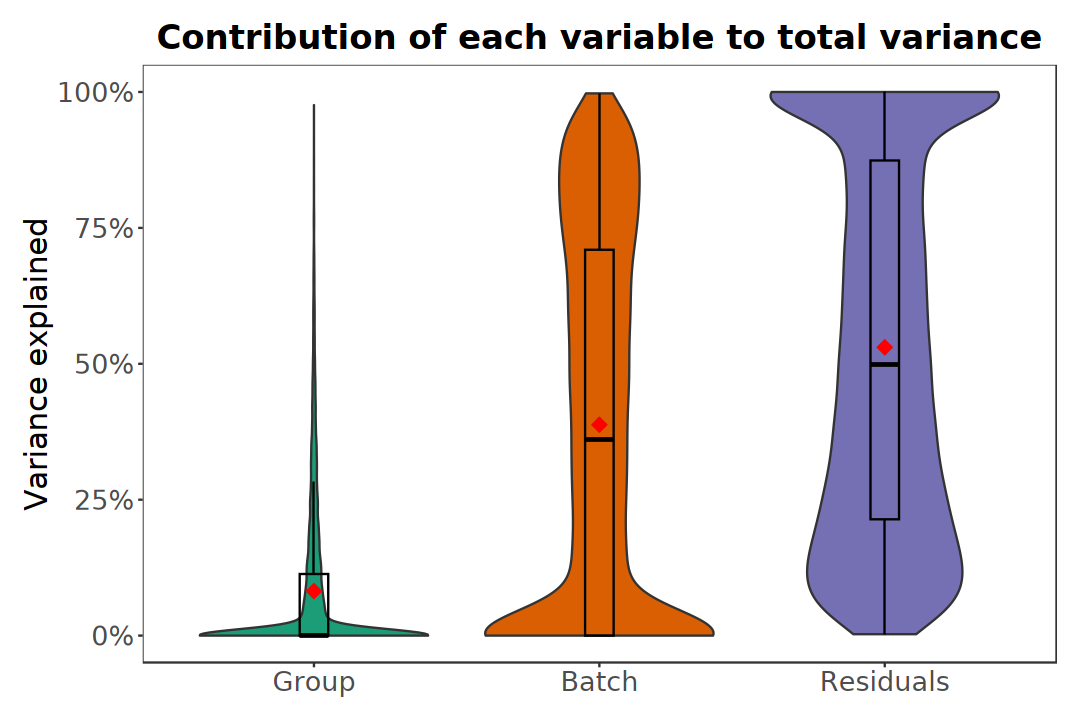

In [52]:
options(repr.plot.width = 9, repr.plot.height = 6)

varPart |> 
    pivot_longer(
        cols = everything(), names_to = "variation", values_to = "value") |>
    mutate(variation = fct_reorder(variation, value, .fun = median)) |>
    ggplot(aes(x = variation, y = value)) +
        geom_violin(
            aes(fill = variation), scale = "width", width = 0.8, alpha = 1) +
        geom_boxplot(
            fill = "white", color = "black", width = 0.1, outlier.shape = NA, alpha = 0) +
        stat_summary(
            fun = mean, geom = "point", color = "red", fill = "red", shape = 23, size = 3) +
        scale_fill_brewer(palette = "Dark2") +
        scale_y_continuous(labels = scales::label_percent(accuracy = 1)) +
        labs(
            title = "Contribution of each variable to total variance", 
            x = NULL, y = "Variance explained") +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.position = "none",
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

In [53]:
suppressPackageStartupMessages(library(gghalves))

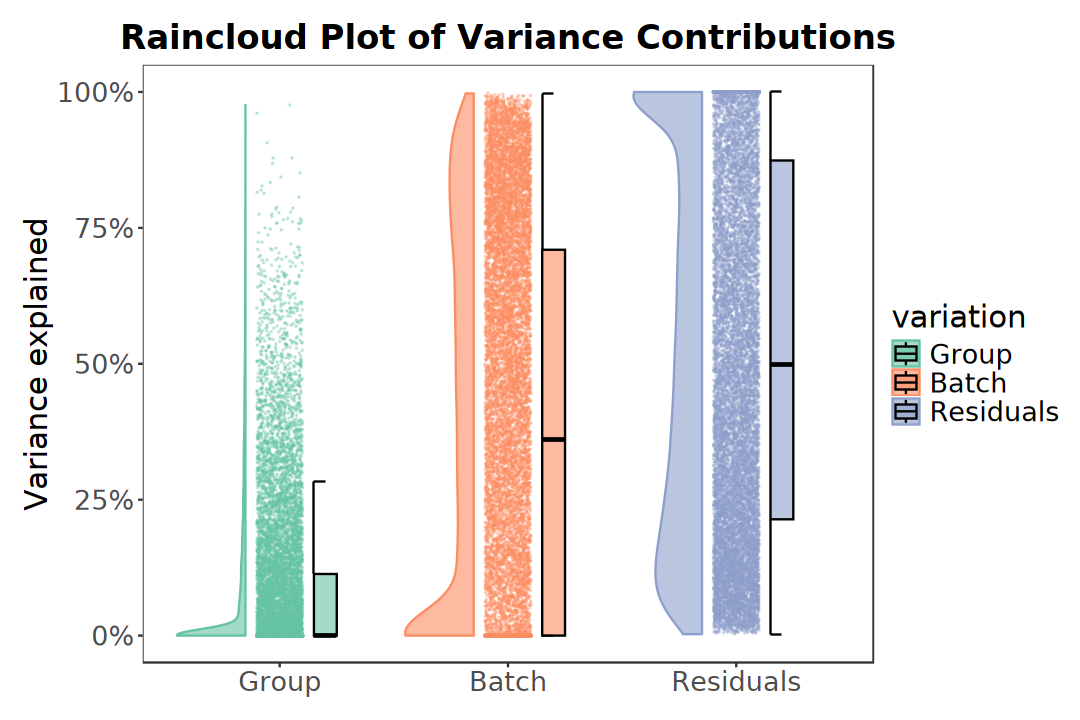

In [54]:
options(repr.plot.width = 9, repr.plot.height = 6)

varPart |> 
    pivot_longer(
        cols = everything(), names_to = "variation", values_to = "value") |>
    mutate(variation = fct_reorder(variation, value, .fun = median)) |>
    ggplot(aes(x = variation, y = value, color = variation, fill = variation)) +
        geom_half_violin(
            position = position_nudge(x = -0.15), scale = "width", 
            side = "l", width = 0.6, trim = TRUE, alpha = 0.6) +
        geom_jitter(width = 0.1, size = 0.01, alpha = 0.3) + 
        geom_half_boxplot(
            position = position_nudge(x = 0.15), side = "r", width = 0.2, 
            outlier.shape = NA, alpha = 0.6, color = "black") +
        scale_fill_brewer(palette = "Set2") +
        scale_color_brewer(palette = "Set2") +
        scale_y_continuous(labels = scales::label_percent(accuracy = 1)) +
        labs(
            title = "Raincloud Plot of Variance Contributions", 
            x = NULL, y = "Variance explained") + 
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

### c). BatchQC

In [55]:
suppressPackageStartupMessages(library(BatchQC))

In [56]:
# eSet <- BatchQC::summarized_experiment(counts(dds), colData(dds))
eSet

class: SummarizedExperiment 
dim: 14087 10 
metadata(0):
assays(1): counts
rownames(14087): 653635 102723897 ... 4576 4571
rowData names(3): symbol type basepairs
colnames(10): Control_rep1 Control_rep2 ... shJAZF1_rep4 shJAZF1_rep5
colData names(5): Accession Cell Group Replicate Batch

In [57]:
eSet_var <- batchqc_explained_variation(
    se = eSet, batch = "Batch", condition = "Group", assay_name = "counts")

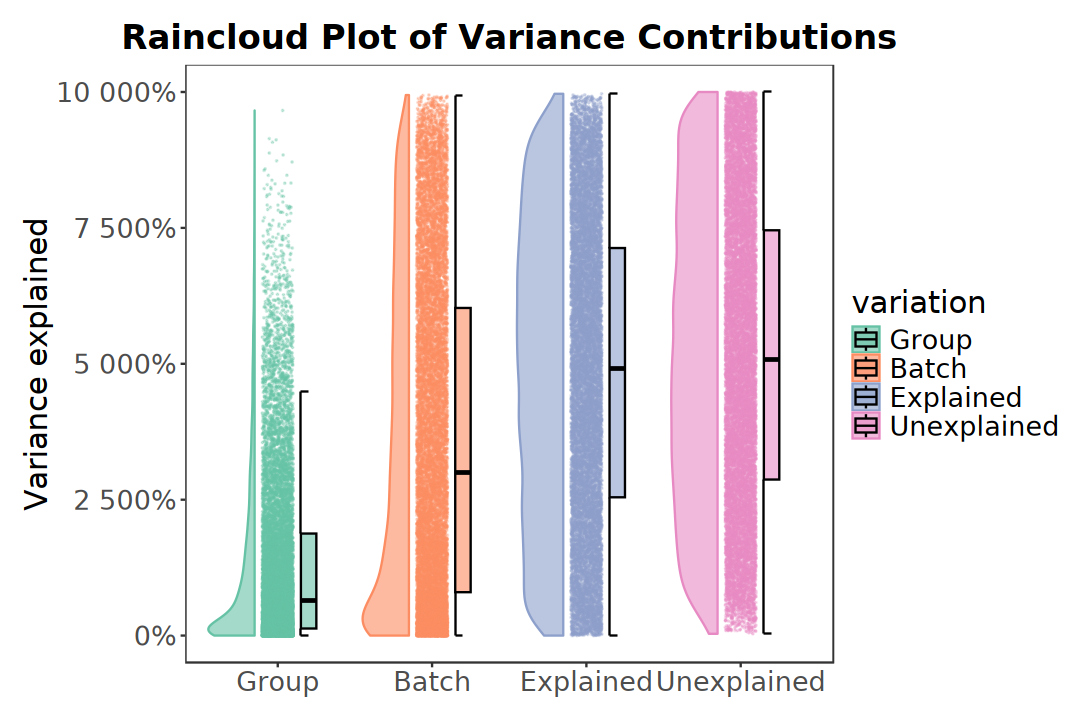

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)

eSet_var$EV_table_ind |> 
    pivot_longer(
        cols = everything(), names_to = "variation", values_to = "value") |>
    mutate(variation = fct_reorder(variation, value, .fun = median)) |>
    ggplot(aes(x = variation, y = value, color = variation, fill = variation)) +
        geom_half_violin(
            position = position_nudge(x = -0.15), scale = "width", 
            side = "l", width = 0.6, trim = TRUE, alpha = 0.6) +
        geom_jitter(width = 0.1, size = 0.01, alpha = 0.3) + 
        geom_half_boxplot(
            position = position_nudge(x = 0.15), side = "r", width = 0.2, 
            outlier.shape = NA, alpha = 0.6, color = "black") +
        scale_fill_brewer(palette = "Set2") +
        scale_color_brewer(palette = "Set2") +
        scale_y_continuous(labels = scales::label_percent(accuracy = 1)) +
        labs(
            title = "Raincloud Plot of Variance Contributions", 
            x = NULL, y = "Variance explained") + 
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

In [59]:
# eSet <- BatchQC::normalize_SE(
#     se = eSet, method = "DESeq", log_bool = FALSE, assay_to_normalize = "counts",
#     output_assay_name = "DESeq_normalized_counts")
# eSet <- BatchQC::batch_correct(
#     se = eSet, method = "ComBat-Seq", assay_to_normalize = "counts", 
#     batch = "Batch", covar = c("Group"), 
#     output_assay_name = "ComBatSeq_corrected")

## 2). Correcting Variation

> Typically used only for visualization

In [60]:
plot_pca <- function(expr_mat, title) {
    pca_res <- expr_mat |> t() |> 
        prcomp(center = TRUE, scale. = FALSE)
    per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)
    pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

    ggplot(pca_df, aes(PC1, PC2)) +
        geom_point(aes(color = Group, shape = Batch), size = 5) +
        scale_color_brewer(palette = "Set1") +
        labs(
            title = bquote("PCA for" ~ -log[2](TPM+1)), 
            x = paste0("PC1: ", per_var[1], "% variance"),
            y = paste0("PC2: ", per_var[2], "% variance")) +
        guides(
            color = guide_legend(override.aes = list(size = 5)), 
            shape = guide_legend(override.aes = list(size = 5))) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

### a). limma-removeBatchEffect

In [61]:
rbe_mat <- removeBatchEffect(
    x = norm_mat, batch = eSet$Batch, group = eSet$Group)

In [62]:
p1 <- plot_pca(rbe_mat, "removeBatchEffect (limma)")

### b). ComBat

> The ComBat function adjusts for known batches using an empirical Bayesian framework and data should be cleaned and normalized.

In [63]:
suppressPackageStartupMessages(library(sva))

In [64]:
mod <- model.matrix(~ 1, data = colData(eSet))

In [65]:
cb_mat <- ComBat(
    dat = norm_mat, batch = eSet$Batch, mod = mod,
    par.prior = TRUE, prior.plots = FALSE)

Found2batches

Adjusting for0covariate(s) or covariate level(s)

Standardizing Data across genes

Fitting L/S model and finding priors

Finding parametric adjustments

Adjusting the Data




In [66]:
p2 <- plot_pca(cb_mat, "ComBat (sva)")

### c). ComBat-seq

> ComBat-Seq is an improved model based on the ComBat framework, uses a negative binomial regression to model batch effects, which specifically targets RNA-Seq count data. It requires untransformed, raw count data to adjust for batch effect.
> - Yuqing Zhang, Giovanni Parmigiani, W Evan Johnson, ComBat-seq: batch effect adjustment for RNA-seq count data, NAR Genomics and Bioinformatics, Volume 2, Issue 3, September 2020, lqaa078, https://doi.org/10.1093/nargab/lqaa078

In [67]:
cbs_counts <- ComBat_seq(
    assay(eSet), batch = eSet$Batch, group = eSet$Group)

Found 2 batches
Using full model in ComBat-seq.
Adjusting for 1 covariate(s) or covariate level(s)
Estimating dispersions
Fitting the GLM model
Shrinkage off - using GLM estimates for parameters
Adjusting the data


In [68]:
tpm <- cbs_counts |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

cbs_mat <- log2(tpm + 1)

In [69]:
p3 <- plot_pca(cbs_mat, "ComBat-seq (sva)")

### d). ComBat-ref

> Building on the foundations of ComBat-seq, ComBat-ref employs a negative binomial model to adjust count data but innovates by using a pooled dispersion parameter for entire batches and preserving count data for the reference batch.
> - Zhang X. Highly Effective Batch Effect Correction Method for RNA-seq Count Data. bioRxiv [Preprint]. 2024 May 5:2024.05.02.592266. doi: 10.1101/2024.05.02.592266.

In [70]:
source("~/software/r/Combat-ref/Combat_ref.R")
source("~/software/r/Combat-ref/helper_seq.R")

In [71]:
cbr_counts <- ComBat_ref(
    assay(eSet), batch = eSet$Batch, group = eSet$Group)

Found 2 batches
Using full model in ComBat-seq.
Estimating dispersions
Batch  1  dispersion =  0.006412474 
Batch  2  dispersion =  0.003586592 
Reference batch:  2 
Fitting the GLM model
Adjusting the data


In [72]:
tpm <- cbr_counts |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

cbr_mat <- log2(tpm + 1)

In [73]:
p4 <- plot_pca(cbr_mat, "ComBat-ref (script)")

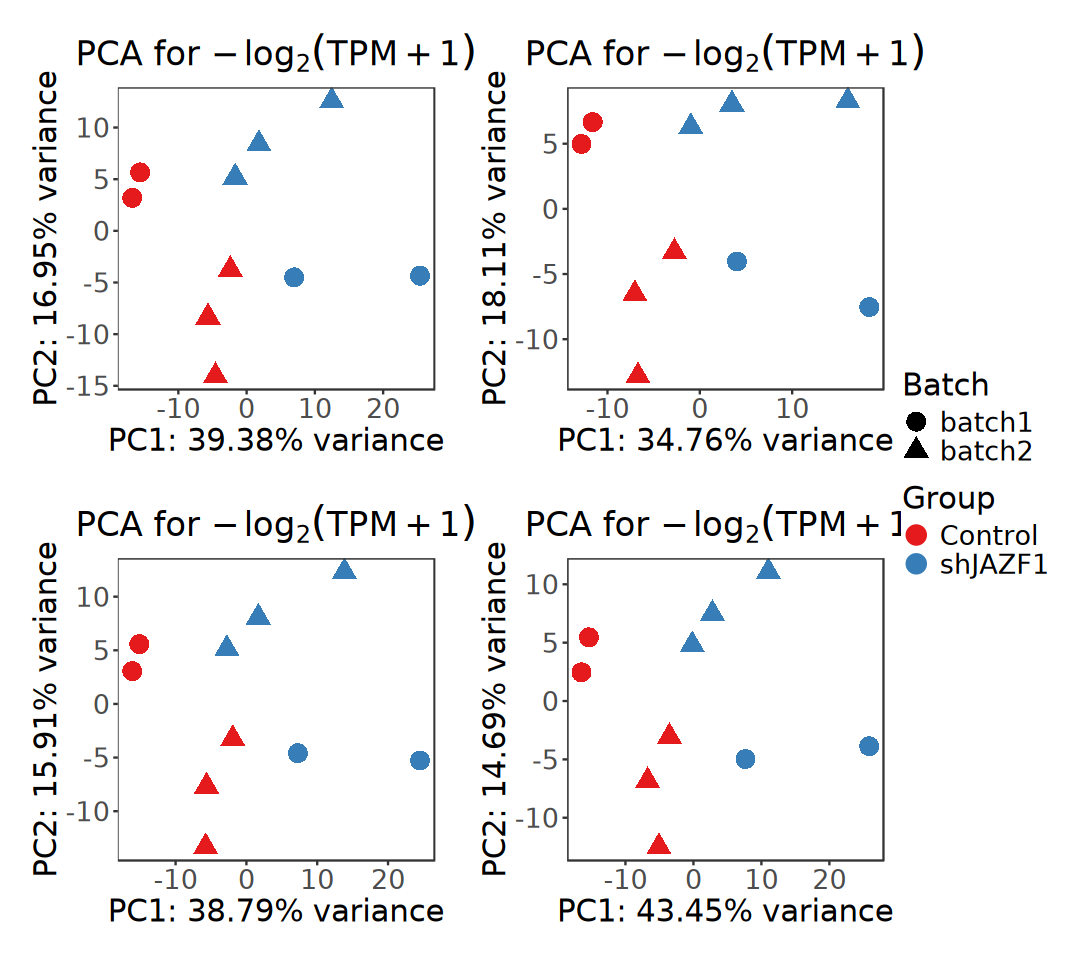

In [74]:
options(repr.plot.width = 9, repr.plot.height = 8)
(p1 + p2) / (p3 + p4) + plot_layout(nrow = 2, guides = "collect")

# 5. DEGs

In [75]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

### Keep Batch

In [76]:
design(dds) <- ~ Group
design(dds)

~Group

In [77]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [78]:
resultsNames(dds)

[1] "Intercept"                "Group_shJAZF1_vs_Control"

In [79]:
# res <- results(
#     dds, name = "Group_shJAZF1_vs_Control", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
res <- lfcShrink(dds, coef = "Group_shJAZF1_vs_Control", type = "apeglm")
summary(res)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895

Warning message in nbinomGLM(x = x, Y = YNZ, size = size, weights = weightsNZ, offset = offsetNZ, :
“the line search routine failed, unable to sufficiently decrease the function value”



out of 14087 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 104, 0.74%
LFC < 0 (down)     : 172, 1.2%
outliers [1]       : 2, 0.014%
low counts [2]     : 274, 1.9%
(mean count < 8)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [80]:
deseq2_keep_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_keep_result$result)


   Up  Down    NS 
   51    91 13945 

### Remove Batch

In [81]:
design(dds) <- ~ Batch + Group
design(dds)

~Batch + Group

In [82]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [83]:
resultsNames(dds)

[1] "Intercept"                "Batch_batch2_vs_batch1"  
[3] "Group_shJAZF1_vs_Control"

In [84]:
# res <- results(
#     dds, name = "Group_shJAZF1_vs_Control", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
res <- lfcShrink(dds, coef = "Group_shJAZF1_vs_Control", type = "apeglm")
summary(res)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 14087 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 653, 4.6%
LFC < 0 (down)     : 897, 6.4%
outliers [1]       : 1, 0.0071%
low counts [2]     : 2458, 17%
(mean count < 34)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [85]:
deseq2_correct_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_correct_result$result)


   Up  Down    NS 
  152   337 13598 

### SVA

> SVA (surrogate variable analysis) identifies and estimates surrogate varaibels for unknown sources of variation. It is appropriate when you know your experimental variable of interest (like the disease state of samples), but unknown sources of variation. It should be run on cleaned and log transformed data. This can be run with or without additional adjustment variables.

In [86]:
suppressPackageStartupMessages(library(sva))

In [87]:
mod <- model.matrix(~ Group + Batch, data = colData(dds))
mod0 <- model.matrix(~ Batch, data = colData(dds))

In [88]:
n.sv <- num.sv(norm_mat, mod, method = "leek")
n.sv

[1] 0

In [89]:
res_sva <- svaseq(norm_mat, mod, mod0, n.sv = 2)

Number of significant surrogate variables is:  2 
Iteration (out of 5 ):1  2  3  4  5  

In [90]:
str(res_sva)

List of 4
 $ sv       : num [1:10, 1:2] 0.275 0.253 -0.193 -0.22 -0.246 ...
 $ pprob.gam: num [1:14087] 0.7411 0.1237 0.0118 0.334 0.2574 ...
 $ pprob.b  : num [1:14087] 0.0841 0.0299 0.3497 0.1205 0.537 ...
 $ n.sv     : num 2


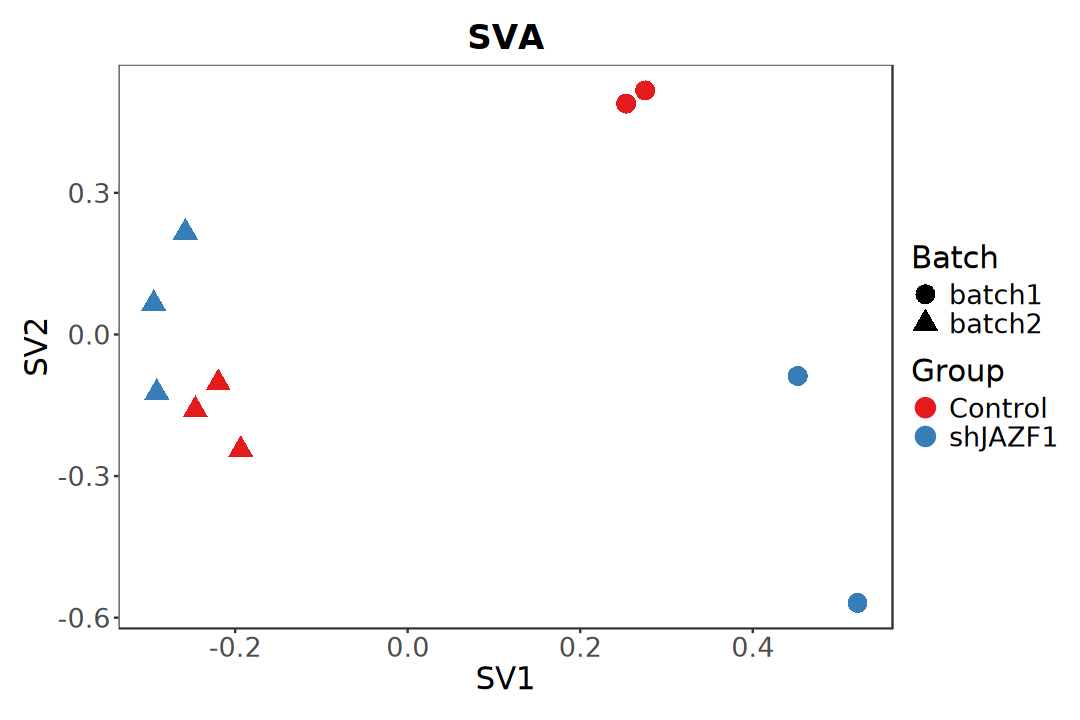

In [91]:
options(repr.plot.width = 9, repr.plot.height = 6)

res_sva$sv |> as.data.frame() |>
    cbind(colData(dds)) |>
    ggplot(aes(V1, V2)) +
        geom_point(
            aes(color = Group, shape = Batch), size = 5) +
        scale_color_brewer(palette = "Set1") +
        labs(title = "SVA", x = "SV1", y = "SV2") +
        guides(
            color = guide_legend(override.aes = list(size = 5)), 
            shape = guide_legend(override.aes = list(size = 5))) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

In [92]:
dds_sva <- dds
dds_sva$SV1 <- res_sva$sv[,1]
dds_sva$SV2 <- res_sva$sv[,2]

design(dds_sva) <- formula(~ SV1 + SV2 + Group)
dds_sva <- DESeq(dds_sva)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [93]:
resultsNames(dds_sva)

[1] "Intercept"                "SV1"                     
[3] "SV2"                      "Group_shJAZF1_vs_Control"

In [94]:
# res <- results(
#     dds_sva, name = "Group_shJAZF1_vs_Control", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
res <- lfcShrink(dds_sva, coef = "Group_shJAZF1_vs_Control", type = "apeglm")
summary(res)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 14087 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 526, 3.7%
LFC < 0 (down)     : 750, 5.3%
outliers [1]       : 0, 0%
low counts [2]     : 3551, 25%
(mean count < 62)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [95]:
deseq2_sva_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_sva_result$result)


   Up  Down    NS 
  108   233 13746 

### RUVSeq

In [96]:
suppressPackageStartupMessages(library(RUVSeq))

In [97]:
seSet <- newSeqExpressionSet(
    counts(dds), phenoData = as.data.frame(colData(dds)))
seSet

SeqExpressionSet (storageMode: lockedEnvironment)
assayData: 14087 features, 10 samples 
  element names: counts, normalizedCounts, offset 
protocolData: none
phenoData
  sampleNames: Control_rep1 Control_rep2 ... shJAZF1_rep5 (10 total)
  varLabels: Accession Cell ... sizeFactor (6 total)
  varMetadata: labelDescription
featureData: none
experimentData: use 'experimentData(object)'
Annotation:  

In [98]:
seSet <- betweenLaneNormalization(seSet, which = "upper")

In [99]:
dds_test <- DESeq(dds)
res_test <- results(dds_test)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [100]:
not.sig <- rownames(res_test)[which(res_test$pvalue > .1)]
empirical <- rownames(eSet)[ rownames(eSet) %in% not.sig ]
seSet <- RUVg(seSet, empirical, k = 2)
pData(seSet)

,Accession,Cell,Group,Replicate,Batch,sizeFactor,W_1,W_2
,<chr>,<chr>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
Control_rep1,GSM4975190,Hela,Control,rep1,batch1,1.0419623,-0.3724907,0.468304242
Control_rep2,GSM4975192,Hela,Control,rep2,batch1,1.0410435,-0.3770310,0.342426233
Control_rep3,GSM4975194,Hela,Control,rep3,batch2,0.9066054,0.2668442,-0.124118401
Control_rep4,GSM4975196,Hela,Control,rep4,batch2,1.0402011,0.2400364,0.004816967
Control_rep5,GSM4975198,Hela,Control,rep5,batch2,1.0785944,0.2445914,-0.148280872
shJAZF1_rep1,GSM4975191,Hela,shJAZF1,rep1,batch1,0.9235016,-0.3769333,-0.669991632
shJAZF1_rep2,GSM4975193,Hela,shJAZF1,rep2,batch1,0.9225045,-0.4203211,-0.138717590
shJAZF1_rep3,GSM4975195,Hela,shJAZF1,rep3,batch2,1.0555191,0.2530096,0.344492507
shJAZF1_rep4,GSM4975197,Hela,shJAZF1,rep4,batch2,1.0297223,0.2891211,-0.173812448


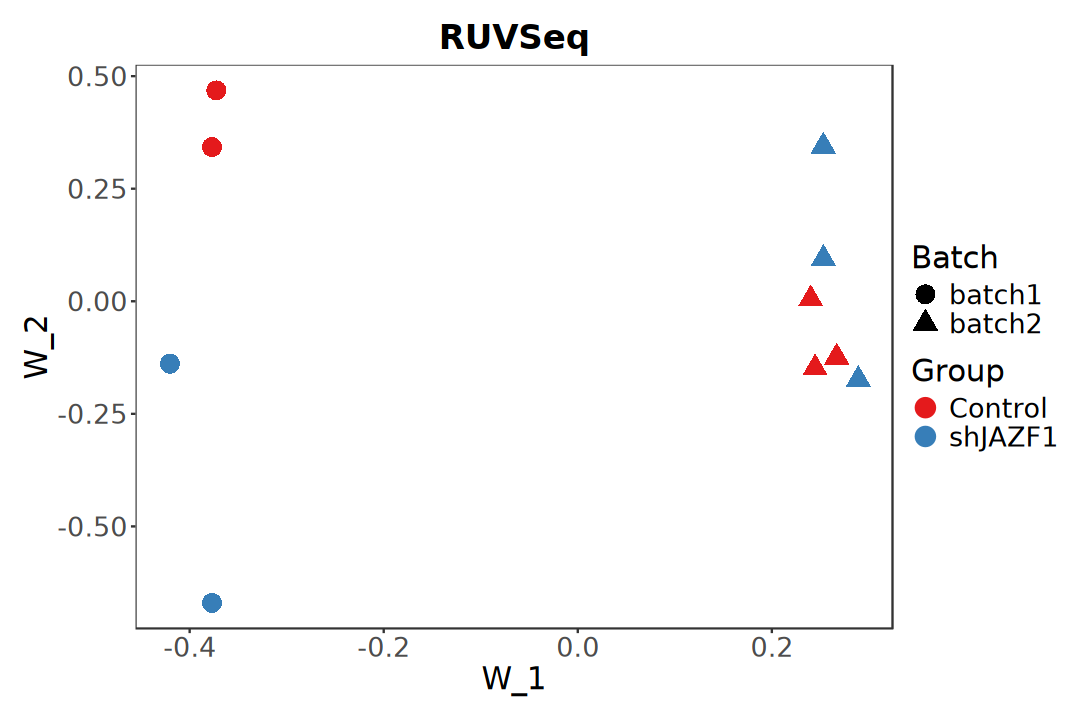

In [101]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pData(seSet), aes(W_1, W_2)) +
    geom_point(
        aes(color = Group, shape = Batch), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "RUVSeq", x = "W_1", y = "W_2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [102]:
dds_ruv <- dds
dds_ruv$W_1 <- seSet$W_1
dds_ruv$W_2 <- seSet$W_2

design(dds_ruv) <- formula(~ W_1 + W_2 + Group)
dds_ruv <- DESeq(dds_ruv)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [103]:
resultsNames(dds_ruv)

[1] "Intercept"                "W_1"                     
[3] "W_2"                      "Group_shJAZF1_vs_Control"

In [104]:
# res <- results(
#     dds_ruv, name = "Group_shJAZF1_vs_Control", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
res <- lfcShrink(dds_ruv, coef = "Group_shJAZF1_vs_Control", type = "apeglm")
summary(res)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 14087 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 494, 3.5%
LFC < 0 (down)     : 737, 5.2%
outliers [1]       : 0, 0%
low counts [2]     : 3824, 27%
(mean count < 71)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [105]:
deseq2_ruvseq_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_ruvseq_result$result)


   Up  Down    NS 
   99   227 13761 

### Evaluate DEGs

In [106]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [107]:
genes_up <- list(
    keep = deseq2_keep_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    rmbatch = deseq2_correct_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    sva = deseq2_sva_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    ruvseq = deseq2_ruvseq_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    keep = deseq2_keep_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    rmbatch = deseq2_correct_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    sva = deseq2_sva_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    ruvseq = deseq2_ruvseq_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [108]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

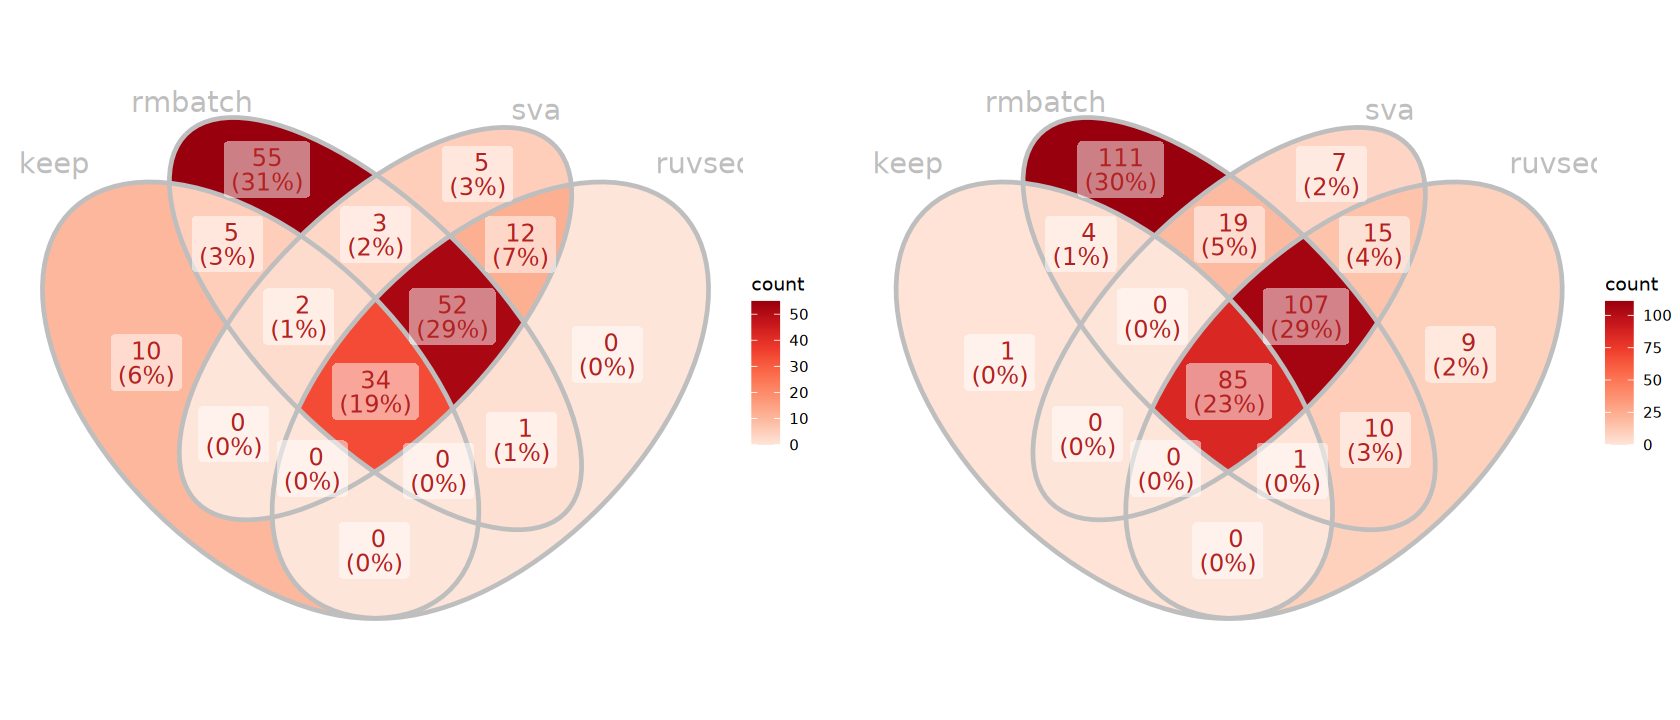

In [109]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

> Trimmed Mean of M-values (TMM)

### a). Negative binomial GLM framework

In [110]:
design <- model.matrix(~ group, data = dgel$samples)
dgel_nbglm <- estimateDisp(dgel, design)
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

edger_lrt_keep_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_lrt_keep_result$result)


   Up  Down    NS 
   36    85 13883 

In [111]:
design <- model.matrix(~ group + Batch, data = dgel$samples)
dgel_nbglm <- estimateDisp(dgel, design)
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

edger_lrt_correct_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_lrt_correct_result$result)


   Up  Down    NS 
  278   665 13061 

### b). Quasi-likelihood pipeline (edgeR v3)

In [112]:
design <- model.matrix(~ group, data = dgel$samples)
dgel_nbglm <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = 2)

edger_qlf_keep_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_qlf_keep_result$result)


   Up  Down    NS 
    2     8 13994 

In [113]:
design <- model.matrix(~ group + Batch, data = dgel$samples)
dgel_nbglm <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = 2)

edger_qlf_correct_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_qlf_correct_result$result)


   Up  Down    NS 
  161   402 13441 

### Evaluate DEGs

In [114]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [115]:
genes_up <- list(
    lrt_keep = edger_lrt_keep_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    lrt_corr = edger_lrt_correct_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    qlf_keep = edger_qlf_keep_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    qlf_corr = edger_qlf_correct_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    lrt_keep = edger_lrt_keep_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    lrt_corr = edger_lrt_correct_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    qlf_keep = edger_qlf_keep_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    qlf_corr = edger_qlf_correct_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [116]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

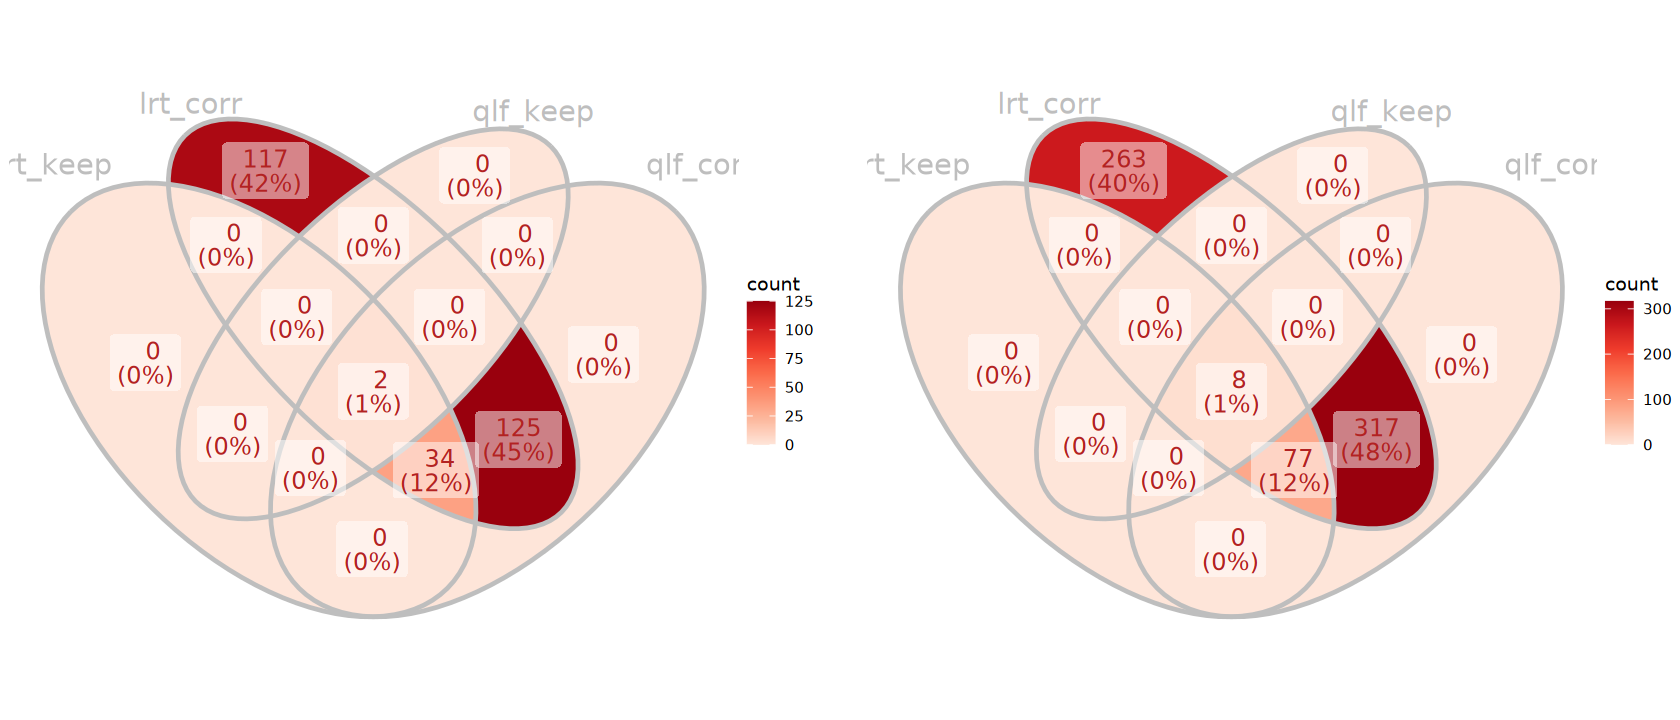

In [117]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 3). limma-voom

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [118]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

limma_keep_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voom_result <- topTable(efit, coef = "groupsiFOXA1", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_keep_result$result)


   Up  Down    NS 
    4    18 13982 

In [119]:
design <- model.matrix(~ group + Batch, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

limma_correct_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voom_result <- topTable(efit, coef = "groupsiFOXA1", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_correct_result$result)


   Up  Down    NS 
  161   439 13404 

### Evaluate DEGs

In [120]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [121]:
genes_up <- list(
    keep = limma_keep_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    corr = limma_correct_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    keep = limma_keep_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    corr = limma_correct_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [122]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

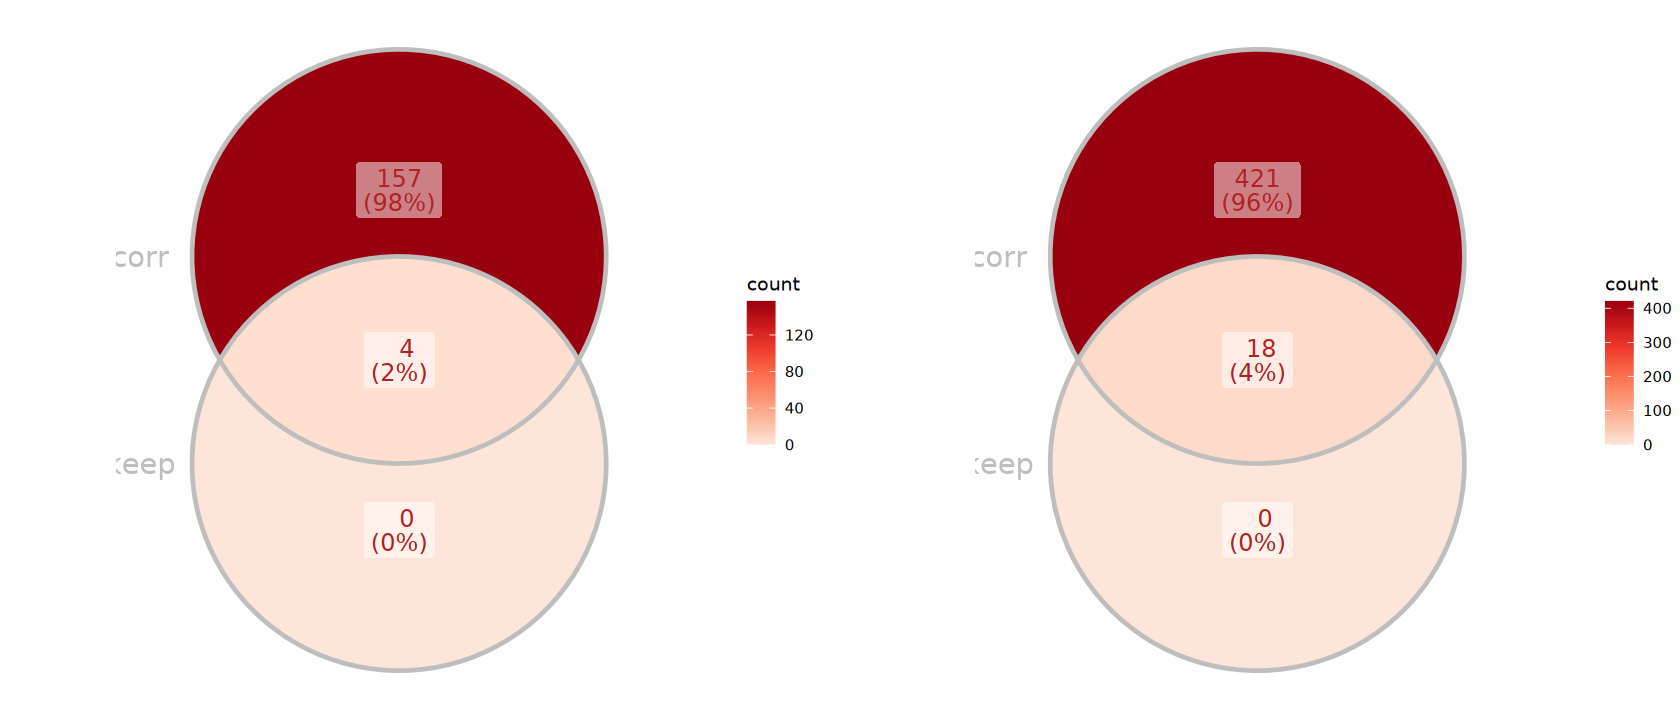

In [123]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Evaluation

In [124]:
add_label <- function(res, symbol_col = "symbol"){
    res |>
        tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 5,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [125]:
deseq2_result <- add_label(deseq2_correct_result, symbol_col = "symbol")
edger_result <- add_label(edger_qlf_correct_result, symbol_col = "symbol")
limma_result <- add_label(limma_correct_result, symbol_col = "symbol")

### P-value Histogram

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_bin()`).”


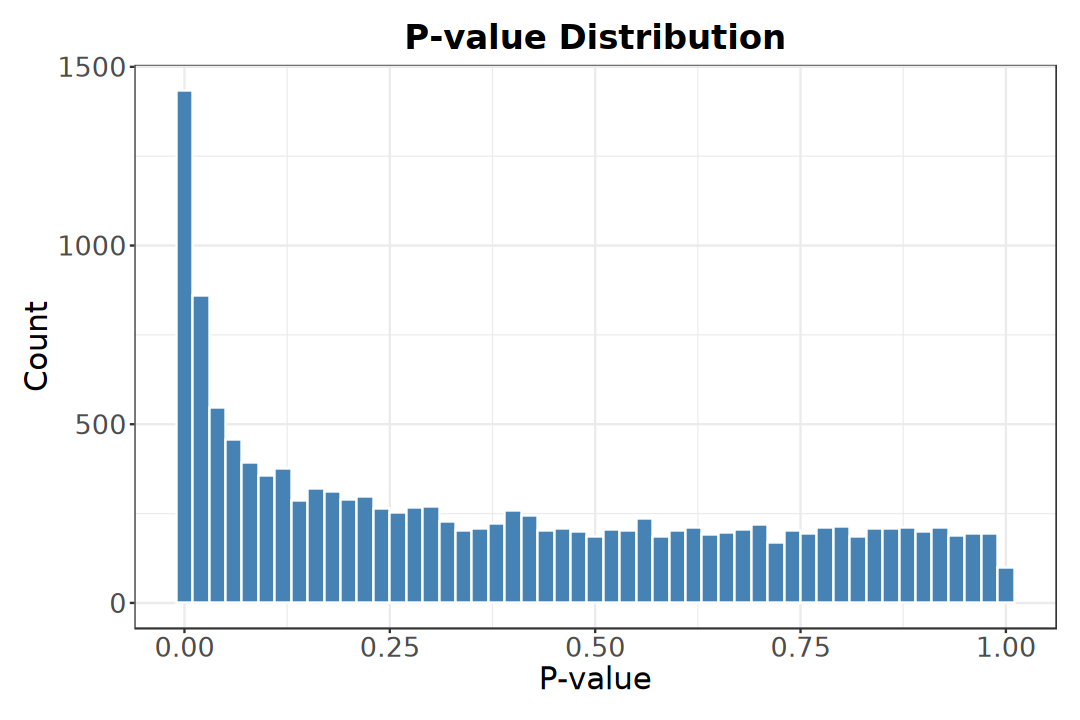

In [126]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution", 
        x = "P-value", y = "Count") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [127]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [128]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

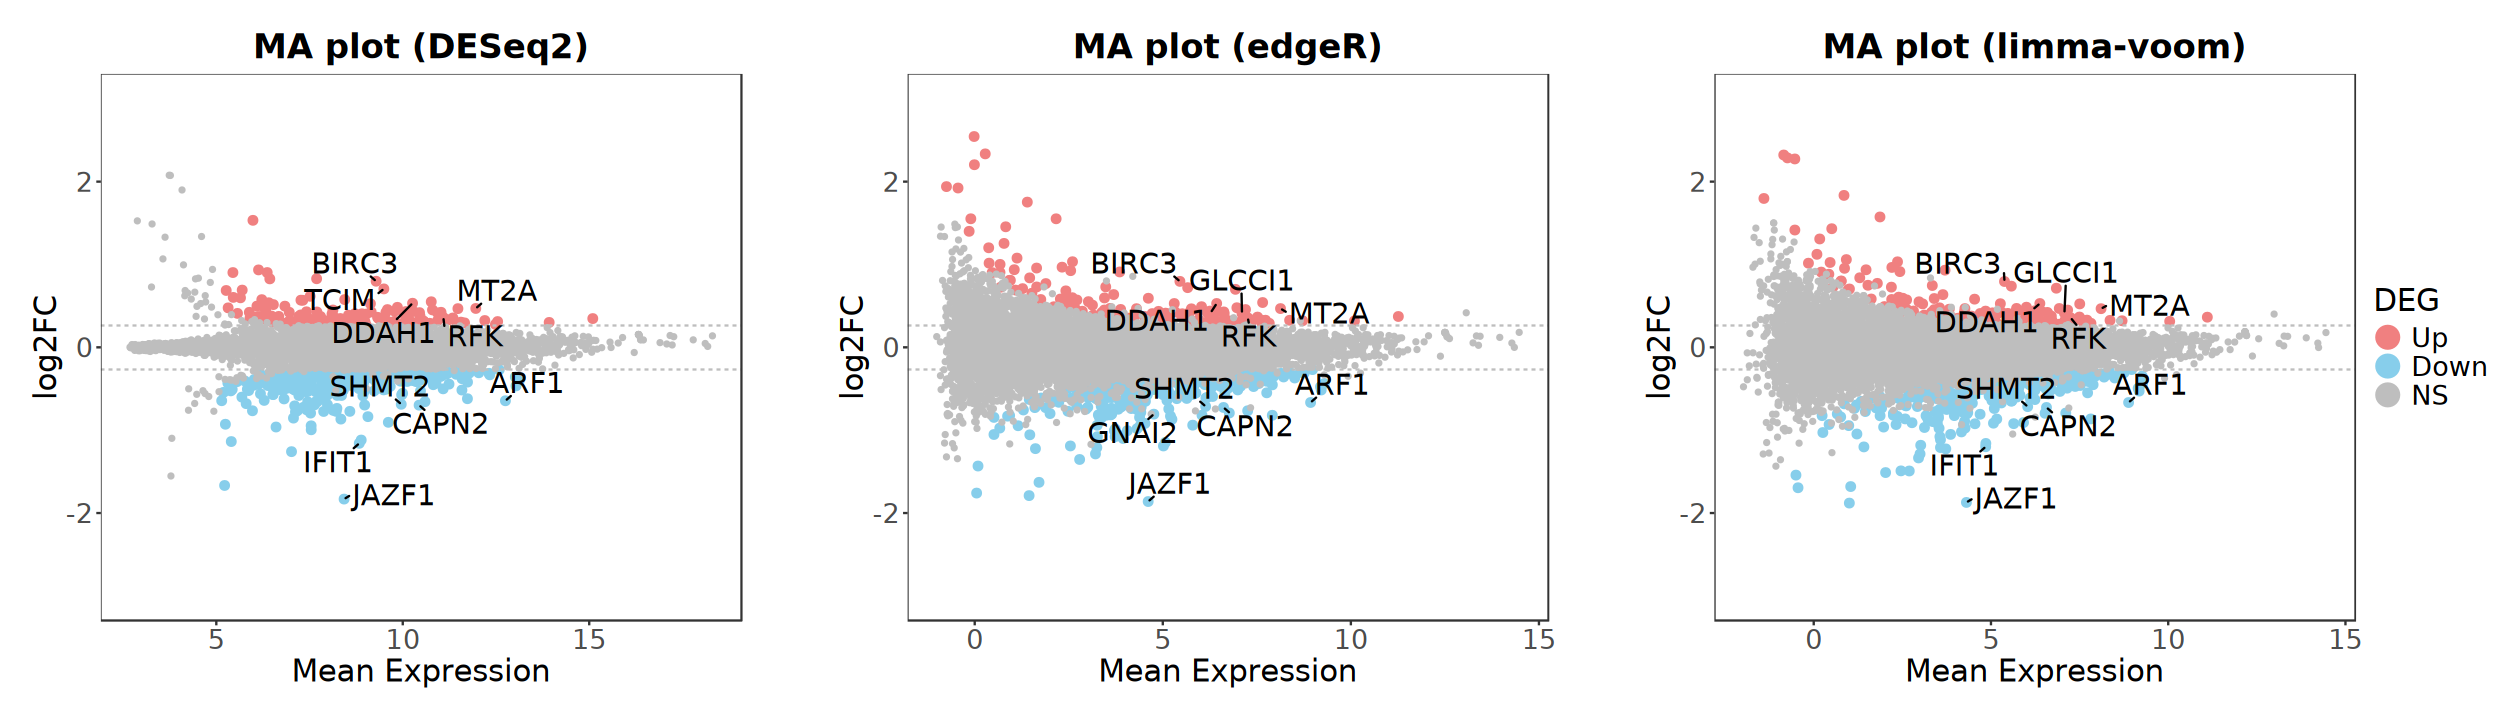

In [129]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [130]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [131]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

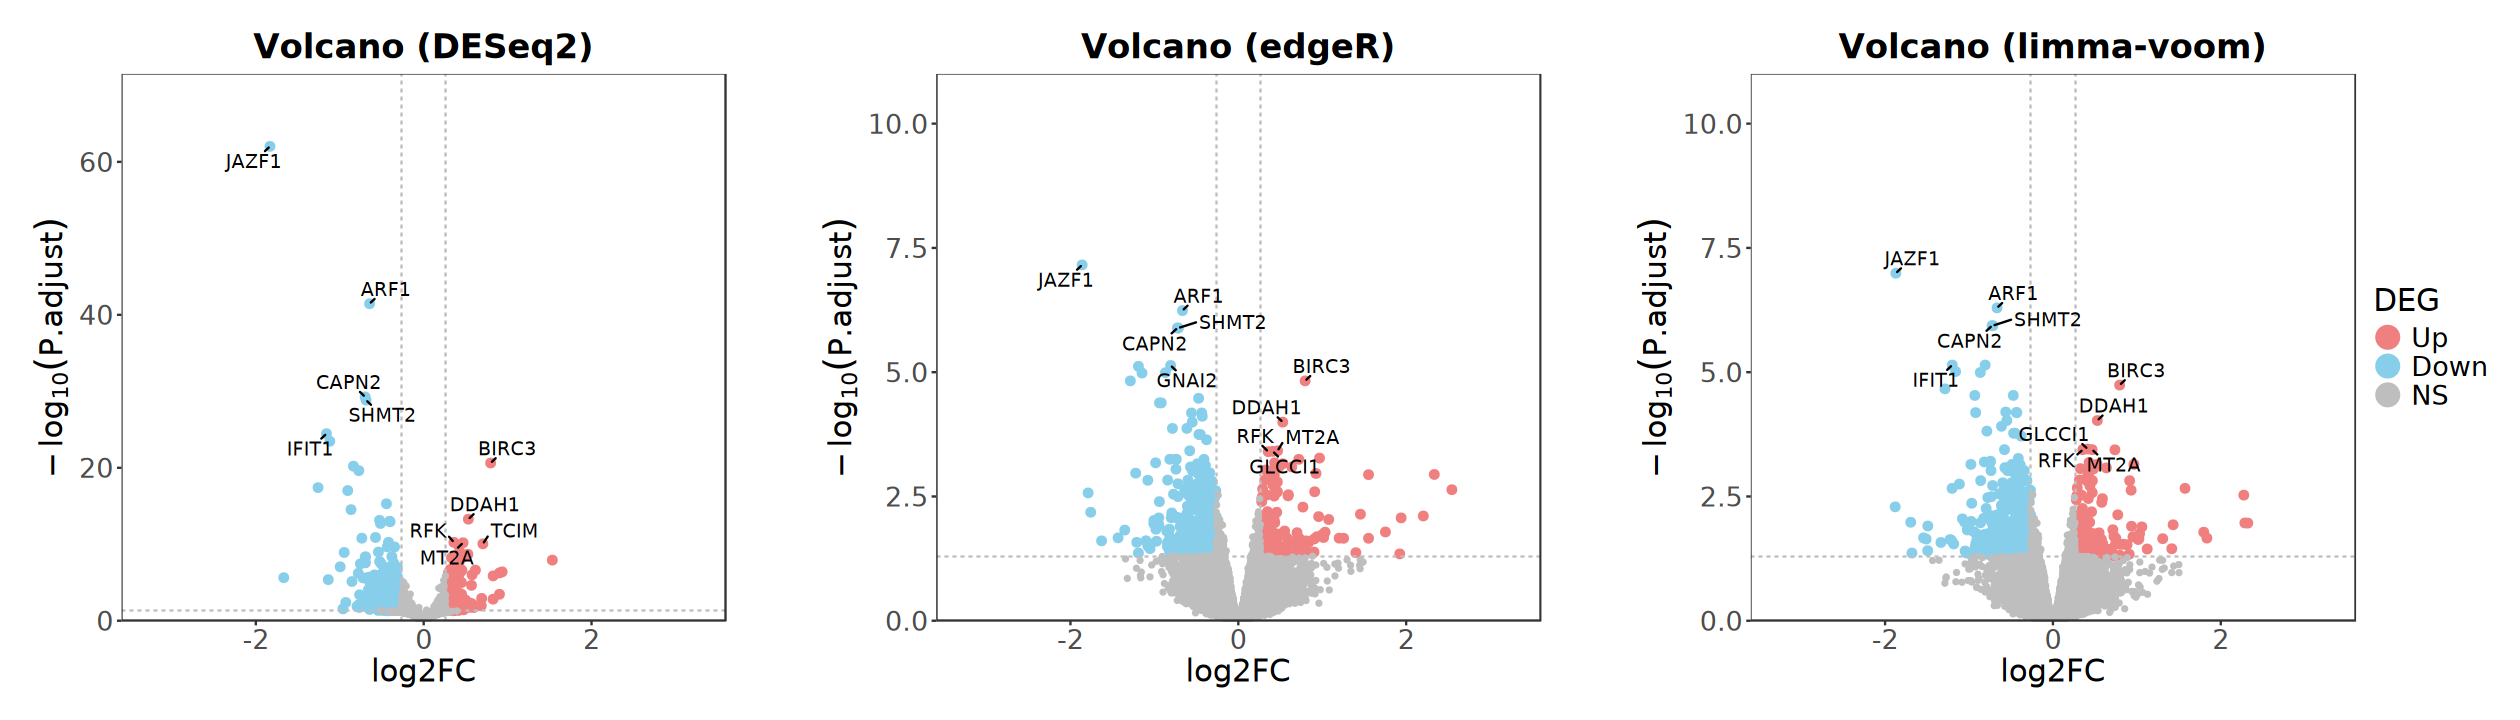

In [132]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [133]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [134]:
genes_up <- list(
    DESeq2 = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    DESeq2 = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [135]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

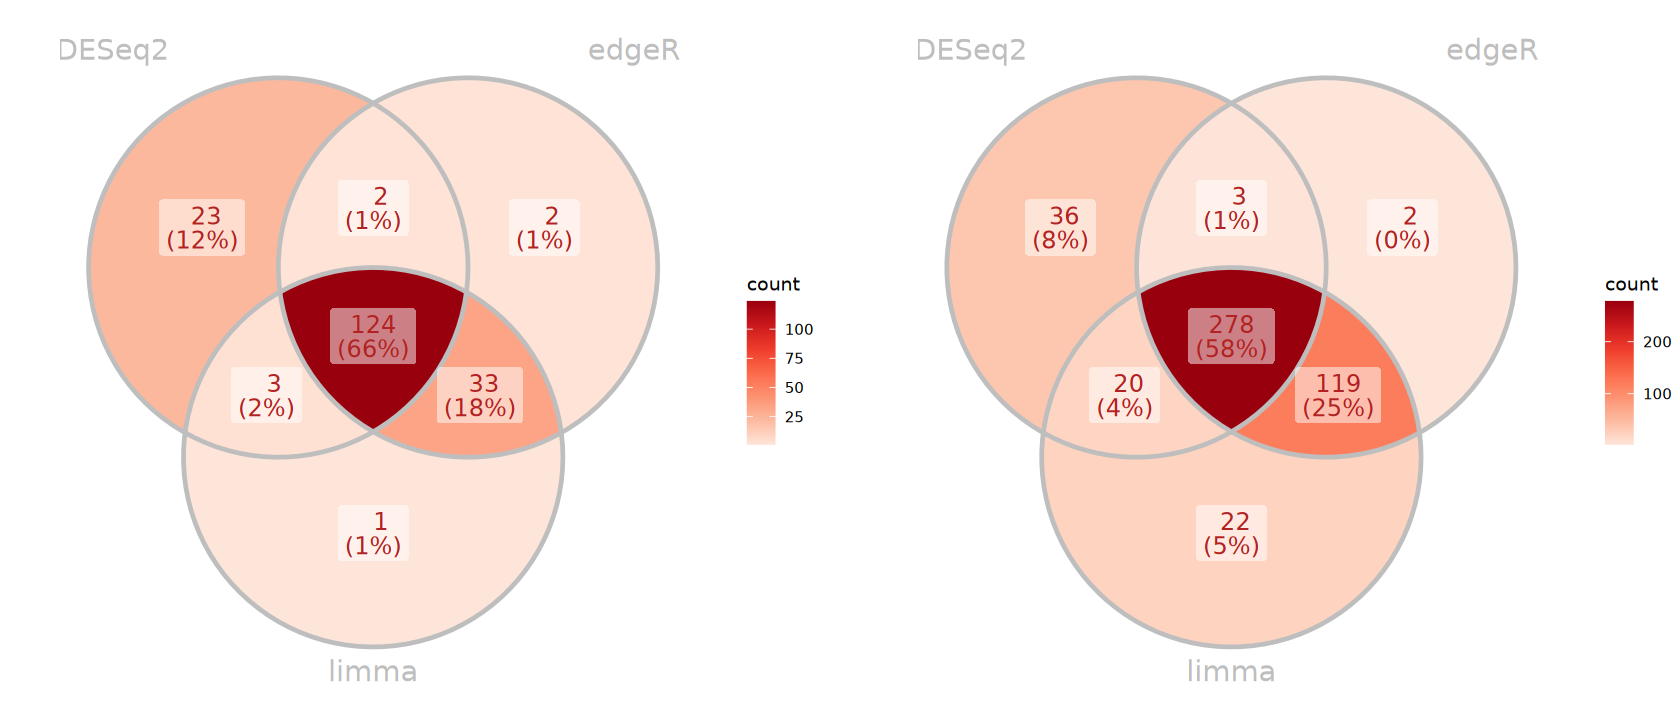

In [136]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

In [137]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


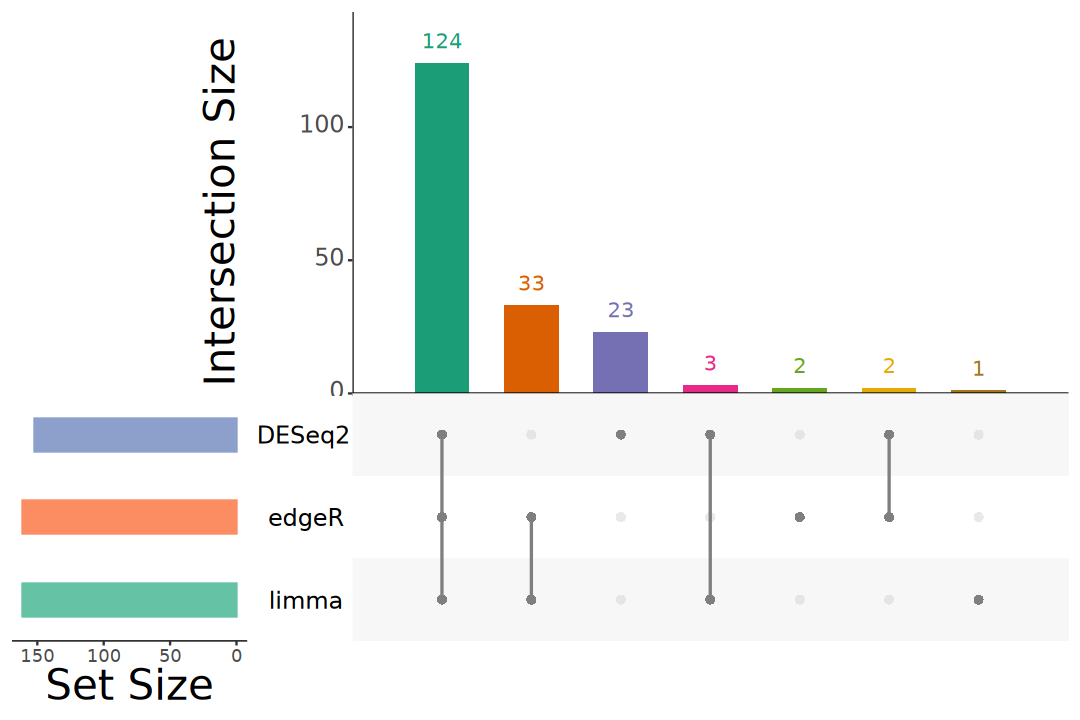

In [138]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

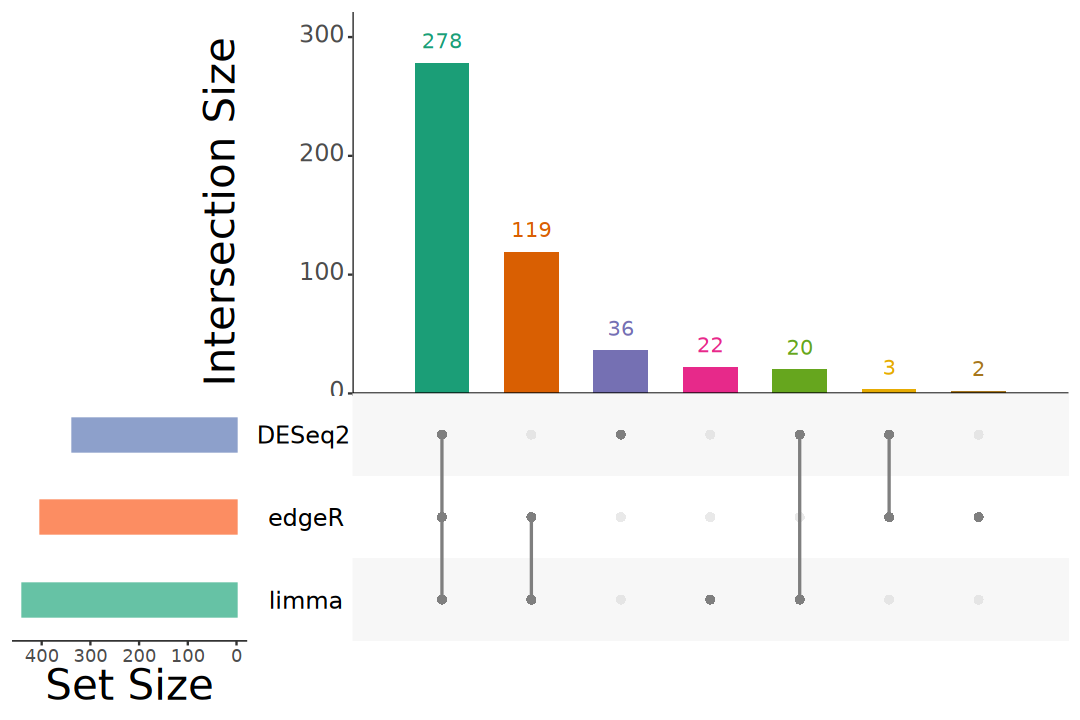

In [139]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

## DEGs Visualization

In [140]:
degs_result <- deseq2_correct_result |>
    rownames_to_column("gene_id") |> 
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein-coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)


   Up  Down    NS 
  152   337 13598 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<chr>
221895,343.0857,-1.8312764,0.10714892,8.037643e-67,9.346171e-63,Down,JAZF1,protein-coding,3239,JAZF1
375,6903.3376,-0.6447260,0.04570595,6.020972e-46,3.500593e-42,Down,ARF1,protein-coding,2350,ARF1
824,1386.4279,-0.6978490,0.05893650,1.365738e-33,5.293599e-30,Down,CAPN2,protein-coding,5707,CAPN2
6472,994.6374,-0.6870461,0.05853881,4.811867e-33,1.398810e-29,Down,SHMT2,protein-coding,2681,SHMT2
3434,455.2081,-1.1584316,0.10717306,1.496789e-28,3.480932e-25,Down,IFIT1,protein-coding,4728,IFIT1
3433,471.9980,-1.1187492,0.10573304,1.749485e-27,3.390502e-24,Down,IFIT2,protein-coding,3393,NA


In [141]:
max_logfc <- degs_result$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- degs_result$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### MA plot

> - Mean-Difference plot
> - Bland-Altman plot

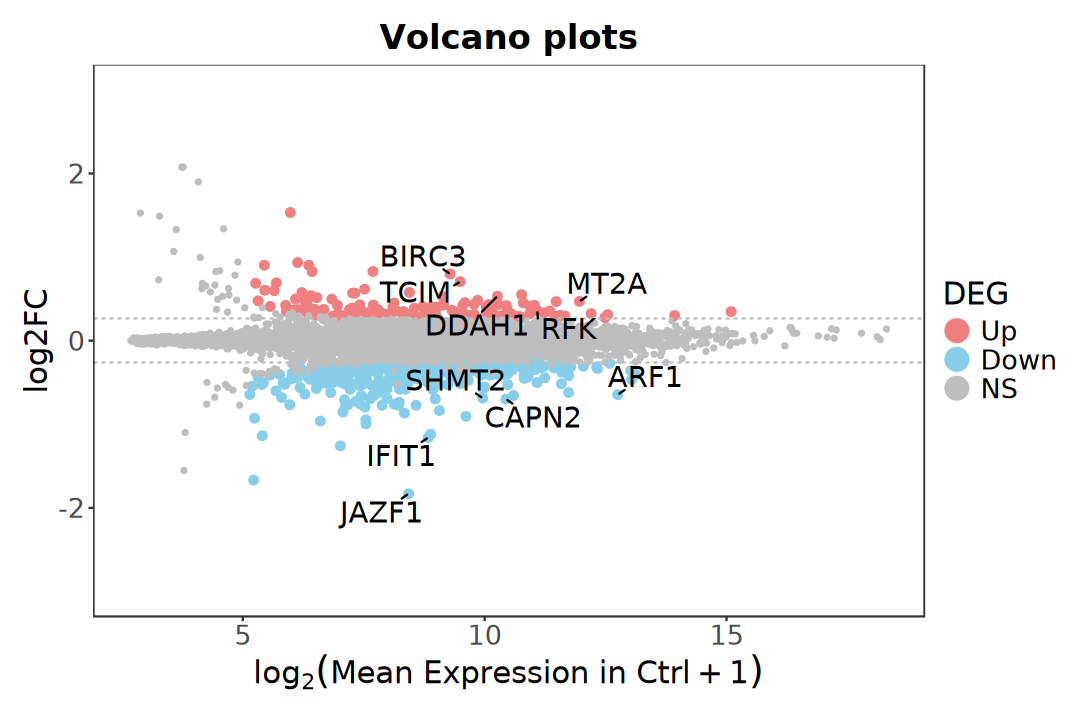

In [142]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = "log2FC") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Volcano

In [143]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [144]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = logFC), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_gradientn(
        colours = brewer.pal(11, 'RdYlBu') |> rev(), 
        limits = c(-max_logfc, max_logfc)) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [145]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)), 
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj)) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
        geom_point(
            aes(color = neglog10_padj_m, size = neglog10_padj), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_gradientn(
            name = expression(-log[10](P.adjust)),
            colours = brewer.pal(11, 'RdBu') |> rev(), 
            limits = c(-min_padj, min_padj),
            breaks = c(-min_padj, 0, min_padj),
            labels = c(min_padj, 0, min_padj)) +
        scale_size_continuous(range = c(1, 3), guide = "none") +
        labs(
            title = "Volcano plots", color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.key.size = unit(1, "cm"),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [146]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +  
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) + 
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142")) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots", 
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

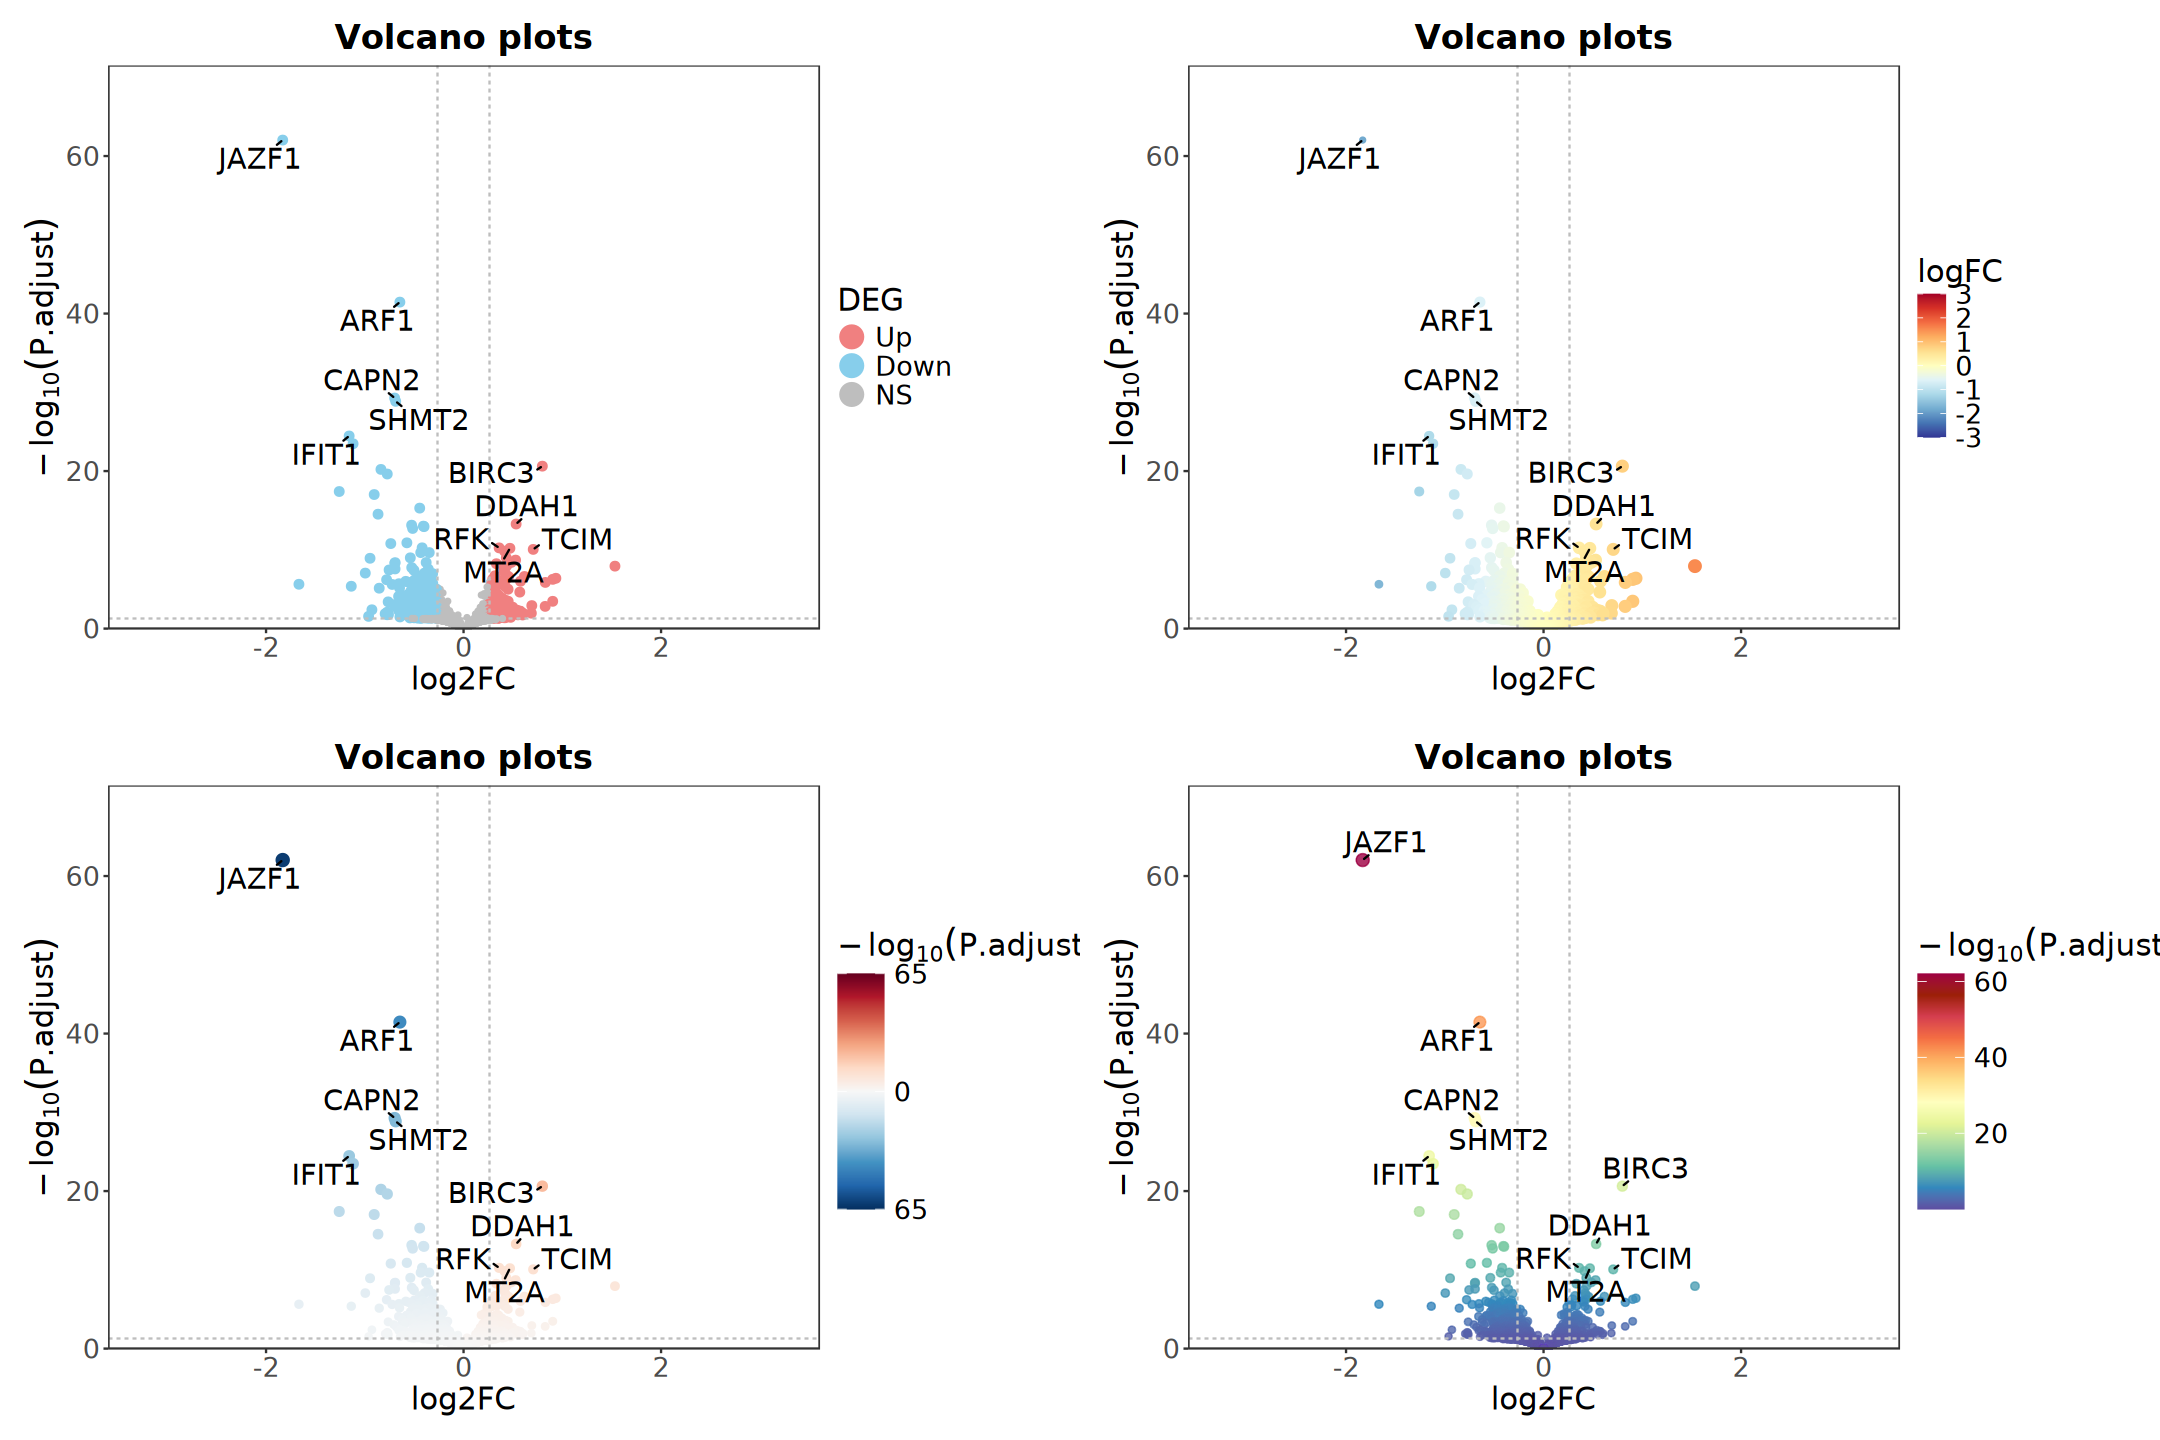

In [147]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4, nrow = 2, align = "hv", axis = "tblr")

### Scatter Plot

In [148]:
ctrl_samples <- colnames(dds)[dds$Group == "Control"]
treat_samples <- colnames(dds)[dds$Group == "shJAZF1"]

mean_expr <- dds |>
    counts(normalized = TRUE) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))) |> 
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [149]:
plot_df <- degs_result |> 
    rownames_to_column(var = "gene_id") |> 
    inner_join(mean_expr, by = "gene_id") |> 
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)) |> 
    drop_na(log2_Ctrl, log2_Treat)

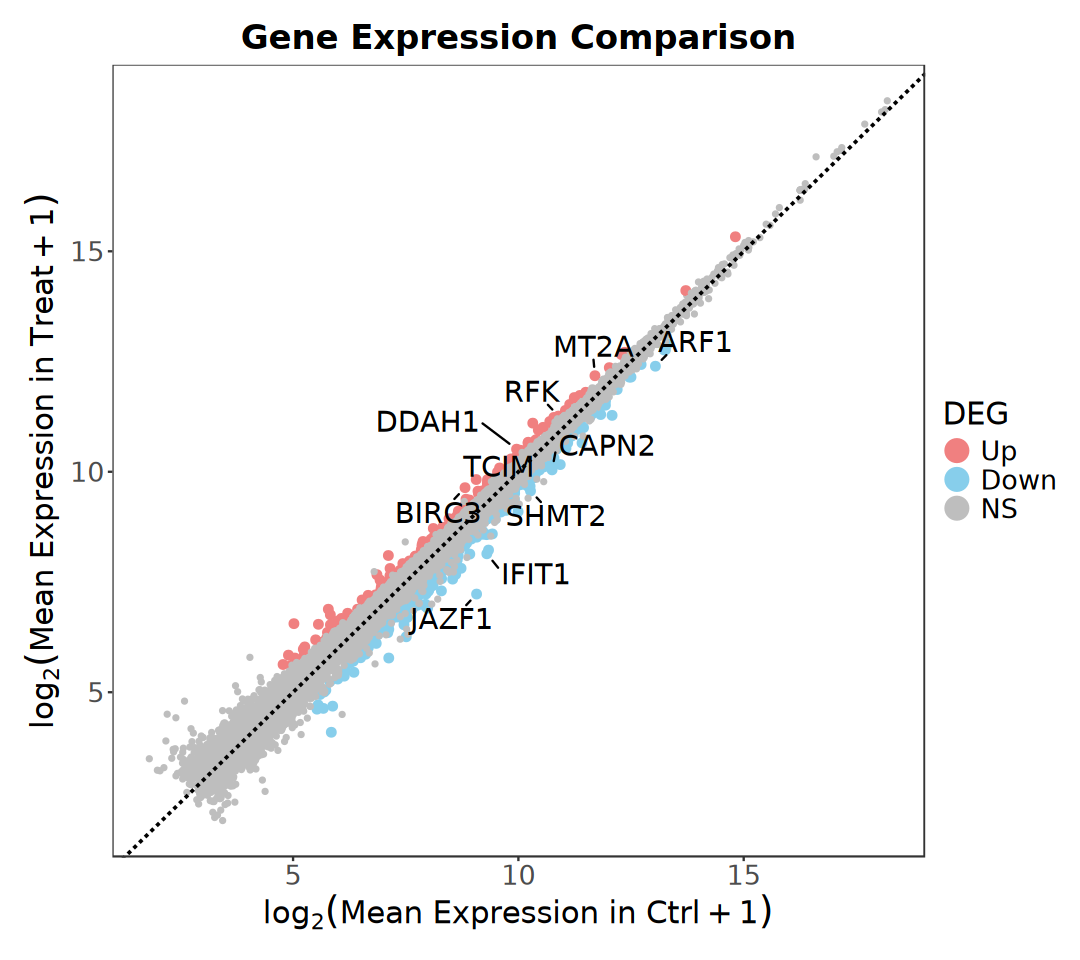

In [150]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "black", linewidth = 0.8) +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    labs(
        title = "Gene Expression Comparison",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))) + 
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [151]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [152]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Batch, Group)

In [153]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
batch_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Batch)),
    levels(eSet$Batch))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Group = group_colors, Batch = batch_colors, 
    Replicate = replicate_colors, DEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

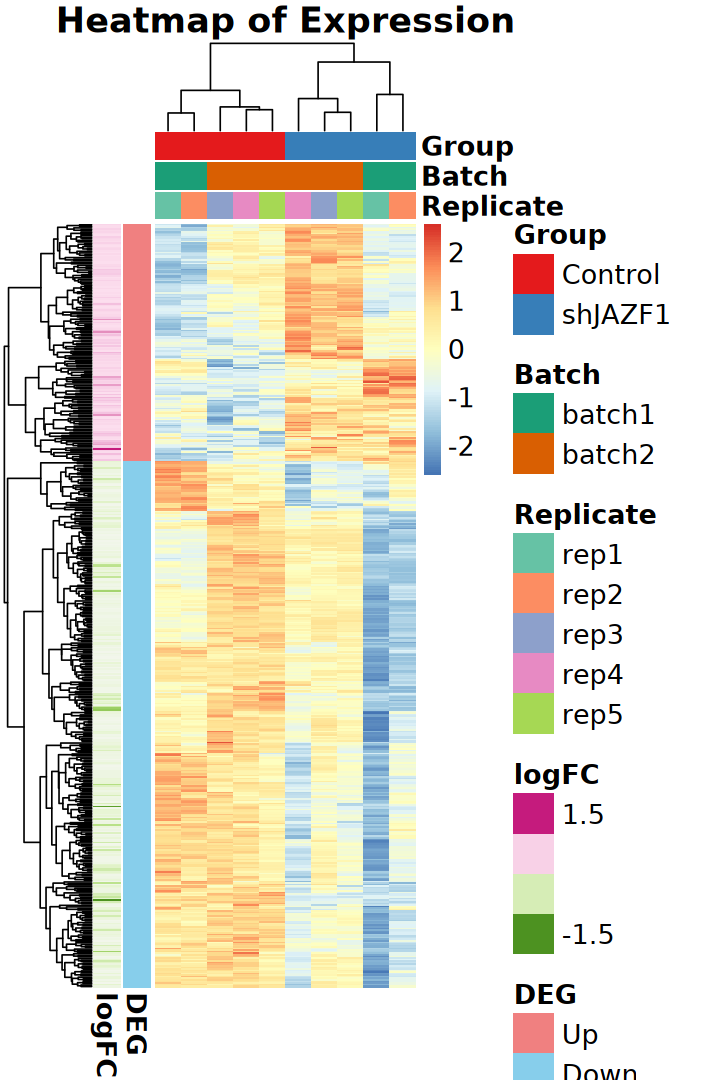

In [154]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [155]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [156]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [157]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
batch_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Batch)),
    levels(eSet$Batch))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [158]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Batch, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Batch = batch_colors,
        Replicate = replicate_colors))

In [159]:
ar <- degs_result |> 
    dplyr::select(logFC, DEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [160]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [161]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Cell, Group, Replicate)

In [162]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_batch <- Legend(
    title = "Batch", labels = levels(dds$Batch))
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_batch, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [163]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

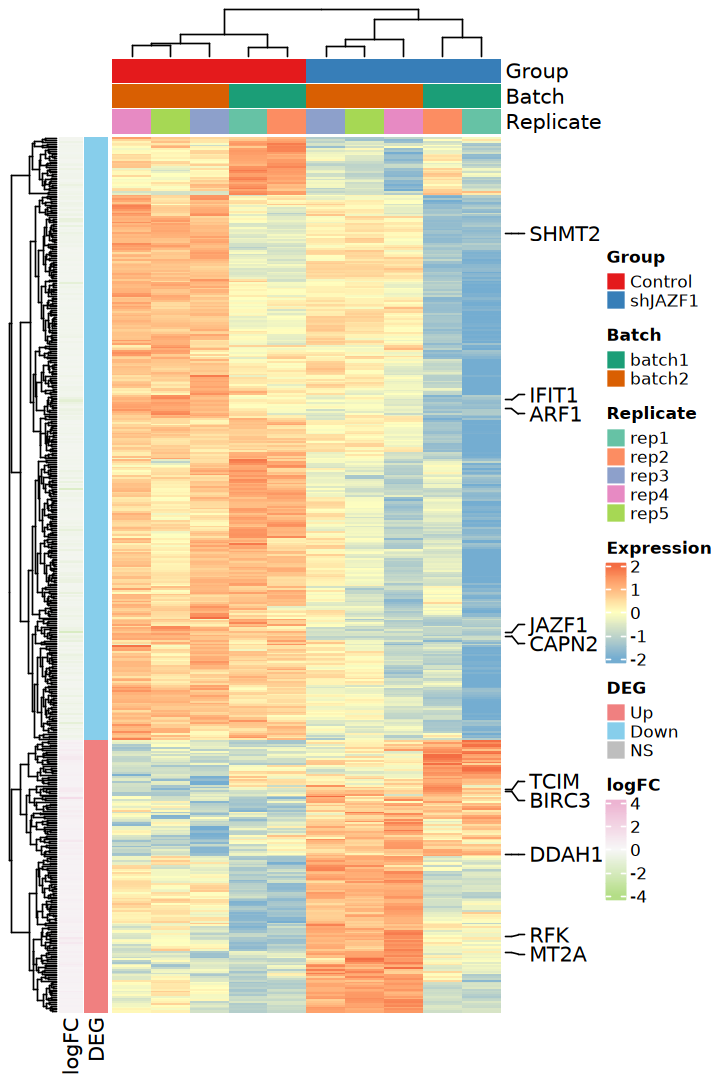

In [164]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [165]:
suppressPackageStartupMessages(library(org.Hs.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [166]:
deseq2_result <- deseq2_result |> rownames_to_column("ENTREZID")
edger_result <- edger_result |> rownames_to_column("ENTREZID")
limma_result <- limma_result |> rownames_to_column("ENTREZID")

In [167]:
extract_gene_lists <- function(
    results_map, gene_col = "SYMBOL", result_col = "result", 
    directions = c("Up", "Down")) {
        
    lapply(names(results_map), function(method) {
        lapply(directions, function(dir) {
            df <- results_map[[method]]
            df[[gene_col]][df[[result_col]] == dir]
        })
    }) |>
    unlist(recursive = FALSE) |>
    setNames(
        nm = as.vector(t(outer(
            names(results_map), directions, paste, sep = "-"))))
}

In [168]:
results_map <- list(
    DESeq2 = deseq2_result, 
    edgeR  = edger_result,
    limma  = limma_result)

genes_list <- extract_gene_lists(
    results_map, gene_col = "symbol", result_col = "result")

In [169]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(c(deseq2_result$symbol, edger_result$symbol)), 
    OrgDb = org.Hs.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [170]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Down,BP,GO:0001649,osteoblast differentiation,18/297,160/10915,0.11250000,4.134470,6.679865,3.344112e-07,0.001188832,0.001053571,18
2,DESeq2-Down,BP,GO:0008202,steroid metabolic process,18/297,188/10915,0.09574468,3.518698,5.825922,3.569968e-06,0.006345618,0.005623639,18
3,DESeq2-Down,BP,GO:0001503,ossification,22/297,280/10915,0.07857143,2.887566,5.351324,7.872586e-06,0.009329015,0.008267597,22


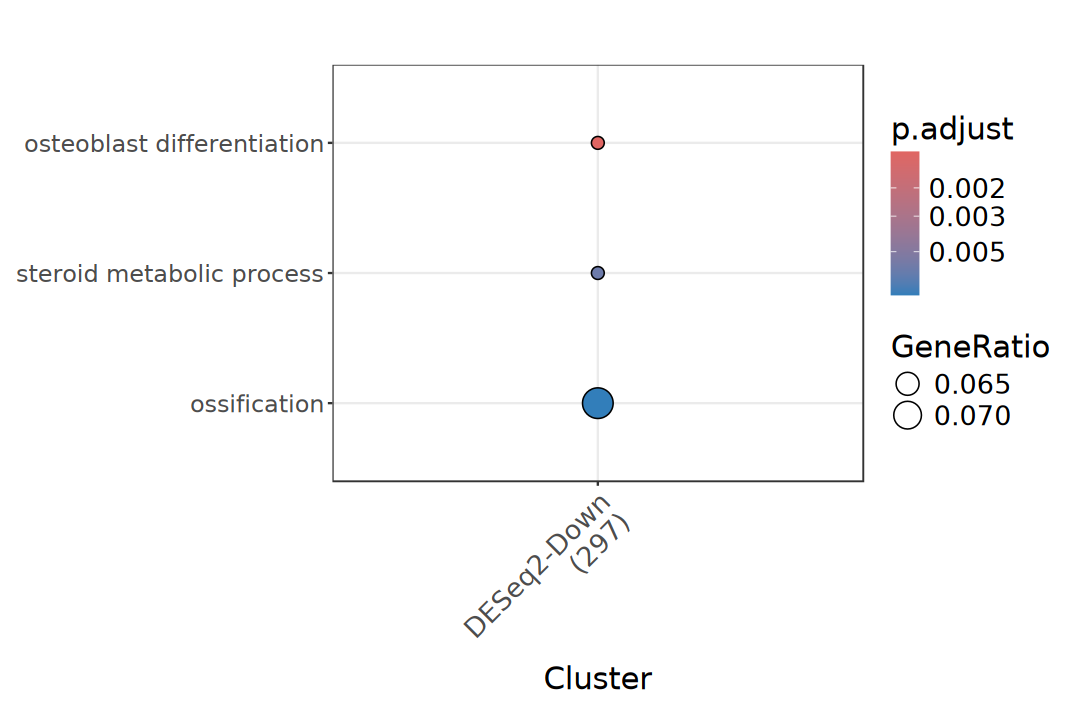

In [171]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [172]:
genes_list <- extract_gene_lists(
    results_map, gene_col = "ENTREZID", result_col = "result")

In [177]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(c(deseq2_result$ENTREZID, edger_result$ENTREZID)), 
    organism = "hsa", pAdjustMethod = "BH",
    pvalueCutoff = 0.05, qvalueCutoff = 0.05, 
    minGSSize = 5, maxGSSize = 500)

Warning message in file(file, "rt"):
“URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached”
Warning message in file(file, "rt"):
“URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached”
Warning message in file(file, "rt"):
“URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached”


In [178]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Down,Organismal Systems,Endocrine system,hsa04935,"Growth hormone synthesis, secretion and action",10/153,86/5386,0.11627907,4.093327,4.944249,0.0001413833,0.02983489,0.02432128,10
2,DESeq2-Down,Human Diseases,Infectious disease: viral,hsa05162,Measles,10/153,93/5386,0.10752688,3.785227,4.632489,0.0002720758,0.02983489,0.02432128,10
3,DESeq2-Down,Human Diseases,Infectious disease: viral,hsa05166,Human T-cell leukemia virus 1 infection,14/153,172/5386,0.08139535,2.865329,4.251061,0.0003364837,0.02983489,0.02432128,14


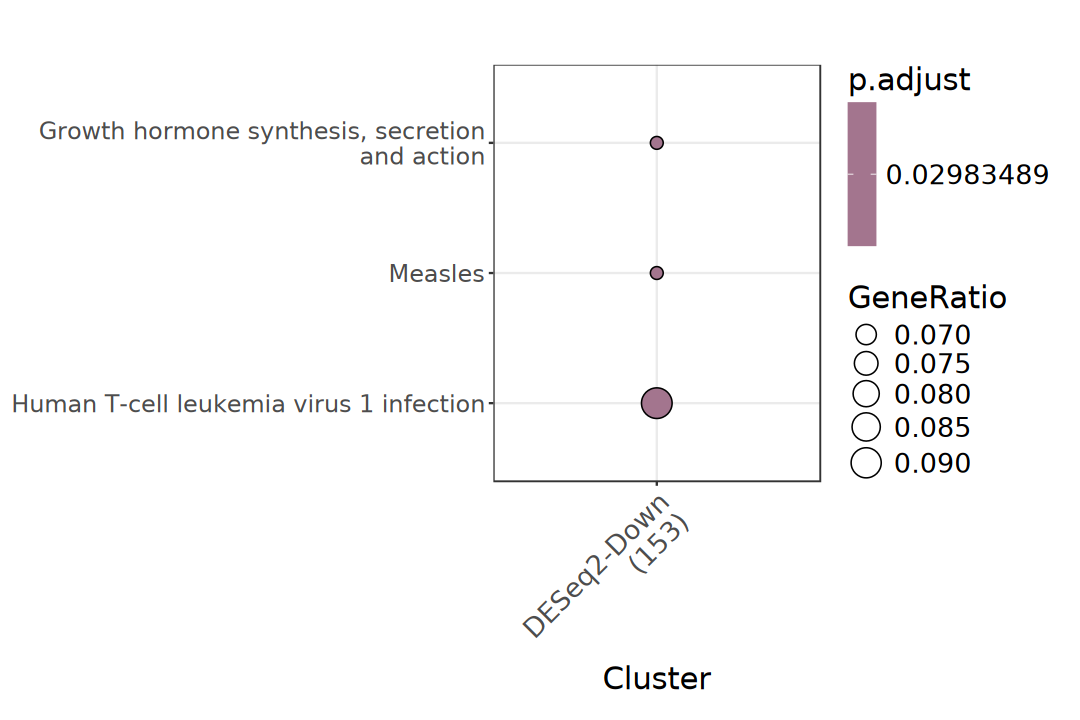

In [179]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)